In [1]:
%load_ext autoreload 
%autoreload

In [2]:
import torch
from torch import nn
import lightning as L
from lightning.pytorch.utilities.model_summary import ModelSummary
from matplotlib import pyplot as plt
import numpy as np
import xarray as xr
import importlib
import os
import pandas
from einops import rearrange, repeat
import sys
import yaml

from src import LTAE, UTAE, utils_model

sys.path.append("/home/hkerino/Documents/next_oso/RandomForest")
from data_functions import dataset, utils_data
from src import lightning_module, metrics



PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_MNT = "/home/hkerino/Documents/nextoso-dataset/data/10m/mnt"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"
PATH_TO_OSO_CLASSES = "/home/hkerino/Documents/nextoso-dataset/data/auxiliary/OSO/oso_classes.csv"

In [3]:
importlib.reload(dataset)
dt = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2, path_mnt=PATH_MNT, path_label=PATH_TO_DATA_label, path_oso_class=PATH_TO_OSO_CLASSES, norm=False,norm_pretrained_alise=True, remove_invalid_temp=True,folds=None, label_type='probas', return_id=True
)

batch_size = 4

dl_train, dl_val, dl_test = dataset.get_loaders(
    path_s2=PATH_TO_DATA_s2,
    path_mnt=PATH_MNT,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    folds_train=[1],
    folds_val=[4],
    folds_test=[5],
    batch_size=batch_size,
    num_worker=4,
    norm=False,
    norm_alise=True,
    shuffle=True,
    label_type='probas',
    use_spatial_coords=False,
    mask_needed=False,
    sequence_packing=False,
    pass_id=False
)

In [46]:
int(dt.__getitem__(0)[-1])

2

In [47]:
inputs, y = next(iter(dl_train))
print(inputs[0].shape)
print(inputs[1].shape)
print(y.shape)

torch.Size([4, 10, 57, 128, 128])
torch.Size([4, 57])
torch.Size([4, 25, 128, 128])


In [48]:
inputs[0][1][-2][-1]

tensor([[ 0.0689,  0.1026,  0.1259,  ..., -0.2043, -0.0611,  0.0324],
        [ 0.0712,  0.1023,  0.1222,  ..., -0.1465,  0.0122,  0.1117],
        [ 0.0523,  0.0871,  0.1094,  ..., -0.1334,  0.0078,  0.1131],
        ...,
        [-0.0223, -0.0216, -0.0111,  ...,  0.0250,  0.0182,  0.0165],
        [-0.0216, -0.0203, -0.0125,  ...,  0.0206,  0.0253,  0.0348],
        [-0.0169, -0.0280, -0.0466,  ...,  0.0398,  0.0500,  0.0665]])

In [17]:
1e-4

0.0001

## Alise test

In [33]:
from Alise import ALISE, sse, transformer, temporal_proj

importlib.reload(ALISE)
importlib.reload(sse)
importlib.reload(temporal_proj)

embedding_dim = 32

embbeding_model = sse.PatchEmbedding(
    sse=sse.Unet(
        inplanes=10,
        planes=embedding_dim,
        encoder_widths=[64, 64, 64, 128],
        decoder_widths=[32, 32, 64, 128],
        encoder_norm="group",
        padding_mode="reflect",
        decoding_norm="group",
        return_maps=False,
        str_conv_k=4,
        str_conv_s=2,
        str_conv_p=1,
        skip_conv_norm="group",
    ),
    tpe=sse.PositionalEncoder(d=embedding_dim),
)

transformer_model = transformer.Transformer(
    d_model=embedding_dim,
    nhead=4,
    dim_feedforward=embedding_dim*2,
    dropout=0.2,
    batch_first=True,
    num_layers=3,
)

temp_proj_model = temporal_proj.LearnedQMultiHeadAttention(
    n_head=8, d_k=8, d_in=embedding_dim, n_q=1
)

In [22]:
ALISE_encoder = ALISE.ALISE(patch_embedding=embbeding_model,
            temporal_encoder=transformer_model,
            temporal_projector=temp_proj_model)

MLP_Decoder = utils_model.MLPDecoder(mlp=[embedding_dim, 32, 25], dropout=0.2)

classifier = lightning_module.classifier(
    ALISE_encoder,
    MLP_Decoder,
    batch_size=batch_size,
    loss_fn=torch.nn.CrossEntropyLoss(
        ignore_index=0,
    ),
    mask_need=False,
)

summary = ModelSummary(classifier, max_depth=-1)
# print(summary)

In [23]:
out = ALISE_encoder(inputs[0], inputs[1])
print(out.shape)

torch.Size([32768, 32])


In [13]:
out_alise = rearrange(out, '(b h w) c -> b h w c', b=inputs[0].shape[0], h=inputs[0].shape[3], w=inputs[0].shape[4], c=out.shape[1])

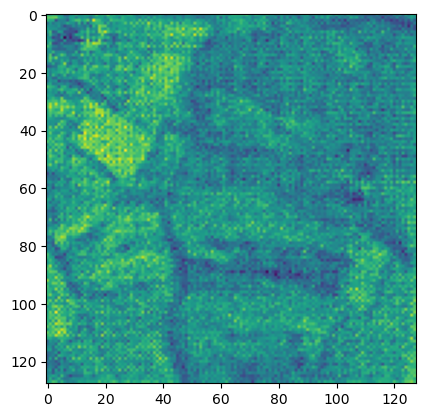

In [18]:
plt.imshow(out_alise[0, :, :, 15].detach().numpy())

In [ ]:
trainer = L.Trainer(
    max_epochs=1,
    profiler=False,
    logger=False,
    callbacks=[],
    limit_train_batches=2,
    limit_val_batches=2,
    limit_test_batches=2,
)
trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name           | Type                      | Params | Mode  | FLOPs
-----------------------------------------------------------------------------
0 | encoder        | ALISE                     | 1.0 M  | train | 0    
1 | decoder        | MLPDecoder                | 1.9 K  | train | 0    
2 | loss_fn        | CrossEntropyLoss          | 0      | train | 0    
3 | acc_metric     | MulticlassAccuracy        | 0      | train | 0    
4 | cm_metric      | MulticlassConfusionMatrix | 0 

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1772252348570/work/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Training: |          | 0/? [00:00<?, ?it/s]

In [10]:
import pandas
norm_alise = pandas.read_csv("/home/hkerino/Documents/nextoso-dataset/data/10m/s2/norm_alise.csv")
print(norm_alise)

  Unnamed: 0     B02     B03     B04     B05     B06     B07     B08     B8A  \
0        med   369.0   610.0   496.0  1072.0  2386.0  2785.0  2946.0  3094.0   
1       qmin   121.0   252.0   172.0   491.0   952.0  1103.0  1186.0  1293.0   
2       qmax  2928.0  2890.0  2866.0  3291.0  4453.0  5160.0  5371.0  5422.0   

      B11     B12  
0  1987.0  1054.0  
1   683.0   365.0  
2  3645.0  2720.0  


In [14]:
norm = norm_alise.iloc[:, 1:].to_numpy(dtype=np.float32)
print(norm)

[[ 369.  610.  496. 1072. 2386. 2785. 2946. 3094. 1987. 1054.]
 [ 121.  252.  172.  491.  952. 1103. 1186. 1293.  683.  365.]
 [2928. 2890. 2866. 3291. 4453. 5160. 5371. 5422. 3645. 2720.]]


In [15]:
s2_data = xr.open_dataset("/home/hkerino/Documents/nextoso-dataset/data/10m/s2/1/fold_1/s2_0002.nc")[["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]].to_dataarray().to_numpy()
print(s2_data.shape)

(10, 97, 128, 128)


In [64]:
s2_data[-1,60,0:10,0:10]

array([[3872, 4020, 4102, 4146, 4134, 4029, 3940, 3927, 4020, 4300],
       [4093, 4217, 4280, 4323, 4310, 4189, 4093, 4103, 4213, 4476],
       [4235, 4319, 4364, 4445, 4478, 4380, 4301, 4334, 4436, 4612],
       [4275, 4326, 4360, 4481, 4564, 4512, 4469, 4524, 4618, 4725],
       [4226, 4255, 4291, 4449, 4583, 4588, 4589, 4665, 4752, 4802],
       [4083, 4144, 4221, 4391, 4533, 4549, 4561, 4647, 4740, 4787],
       [3903, 4019, 4149, 4301, 4417, 4425, 4438, 4531, 4640, 4723],
       [3875, 3990, 4110, 4166, 4210, 4246, 4310, 4440, 4588, 4712],
       [3952, 4032, 4104, 4026, 3978, 4061, 4201, 4378, 4571, 4742],
       [4122, 4150, 4167, 4027, 3950, 4088, 4286, 4473, 4673, 4875]],
      dtype=int16)

In [17]:
torch.from_numpy(
    (s2_data - norm[0][:, None, None, None]) / (norm[2][:, None, None, None]- norm[1][:, None, None, None]
)).float().shape

torch.Size([10, 97, 128, 128])

In [49]:
x = inputs[0].permute(0,2,1,3,4).contiguous()
emb = embbeding_model(x, inputs[1])
emb.shape

torch.Size([4, 57, 32, 128, 128])

In [53]:
x[1][-1][0]

tensor([[ 0.0078,  0.0078,  0.0524,  ..., -0.0609, -0.0264, -0.0296],
        [ 0.0128,  0.0103,  0.0417,  ..., -0.0513, -0.0189, -0.0096],
        [ 0.0232,  0.0089,  0.0392,  ..., -0.0378, -0.0050, -0.0071],
        ...,
        [-0.0321, -0.0281, -0.0292,  ..., -0.0481, -0.0460, -0.0445],
        [-0.0271, -0.0214, -0.0242,  ..., -0.0381, -0.0424, -0.0460],
        [-0.0214, -0.0175, -0.0217,  ..., -0.0378, -0.0456, -0.0438]])

In [56]:
emb[3][-1][0]

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], grad_fn=<SelectBackward0>)

## Labels type

In [151]:
label_id = '0100.nc'
label = xr.open_dataset(os.path.join(PATH_TO_DATA_label,f'label_{label_id}')) 

In [152]:
label

<xarray.Dataset> Size: 1MB
Dimensions:                                (y: 128, x: 128, dim_0: 0)
Coordinates:
  * y                                      (y) float32 512B 6.832e+06 ... 6.8...
  * x                                      (x) float32 512B 8.997e+05 ... 9.0...
Dimensions without coordinates: dim_0
Data variables: (12/20)
    1_Urbain dense                         (y, x) float32 66kB ...
    2_Urbain diffus                        (y, x) float32 66kB ...
    3_Zones industrielles et commerciales  (y, x) float32 66kB ...
    4_Routes                               (y, x) float32 66kB ...
    6_Céréales à paille                    (y, x) float32 66kB ...
    9_Tournesol                            (y, x) float32 66kB ...
    ...                                     ...
    23_Eau                                 (y, x) float32 66kB ...
    24_Serres                              (y, x) float32 66kB ...
    entropy_proba                          (y, x) float32 66kB ...
    max_class_1                            (y, x) int16 33kB ...
    max_probability                        (y, x) float32 66kB ...
    crs                                    (dim_0) float64 0B ...
Attributes:
    year:        2020
    id:          D055_2018-Z9_AN_T31UFP
    size:        128
    resolution:  10m
    crs:         EPSG:2154

In [131]:
labels_names = pandas.read_csv(PATH_TO_OSO_CLASSES).get("name_class")

In [132]:
list_names = []
for i, label_name in enumerate(labels_names):
    list_names.append(str(i) + "_" + str(label_name))

In [158]:
list_names

['0_nan',
 '1_Urbain dense',
 '2_Urbain diffus',
 '3_Zones industrielles et commerciales',
 '4_Routes',
 "5_Oléagineux d'hiver",
 '6_Céréales à paille',
 '7_Protéagineux de printemps',
 '8_Soja',
 '9_Tournesol',
 '10_Maïs',
 '11_Riz',
 '12_Tubercules/racines',
 '13_Prairies',
 '14_Vergers',
 '15_Vignes',
 '16_Forêts de feuillus',
 '17_Forêts de conifères',
 '18_Pelouses',
 '19_Landes',
 '20_Surfaces minérales',
 '21_Plages et dunes',
 '22_Glaciers et neiges éternelles',
 '23_Eau',
 '24_Serres']

In [ ]:
labels_probas = np.zeros((25,128,128))

for k, l in enumerate(list_names):
    if l in list(label.data_vars):
        labels_probas[k, :, :] = label[l].data


1_Urbain dense
1
2_Urbain diffus
2
3_Zones industrielles et commerciales
3
4_Routes
4
6_Céréales à paille
6
9_Tournesol
9
10_Maïs
10
13_Prairies
13
16_Forêts de feuillus
16
17_Forêts de conifères
17
18_Pelouses
18
19_Landes
19
20_Surfaces minérales
20
21_Plages et dunes
21
23_Eau
23
24_Serres
24


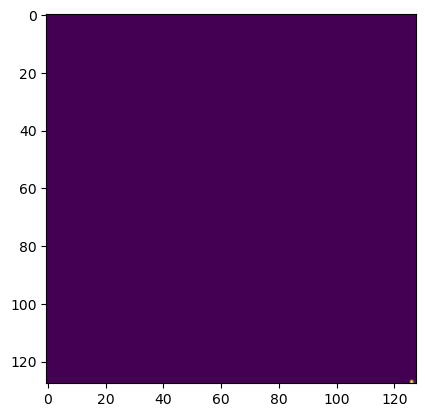

In [164]:
plt.imshow(label['24_Serres'].data)

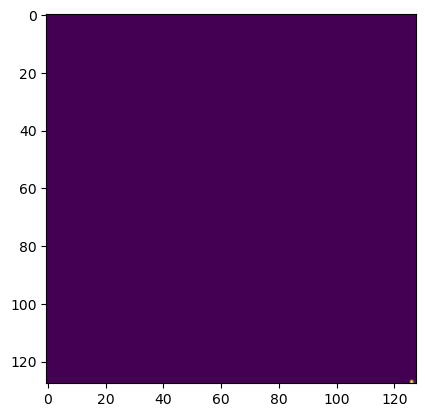

In [156]:
plt.imshow(labels_probas[24,:,:])

In [ ]:
label["17_Forêts de conifères"].data != 0

np.True_

## Metrics

Tensor f-score = 0.47777774930000305


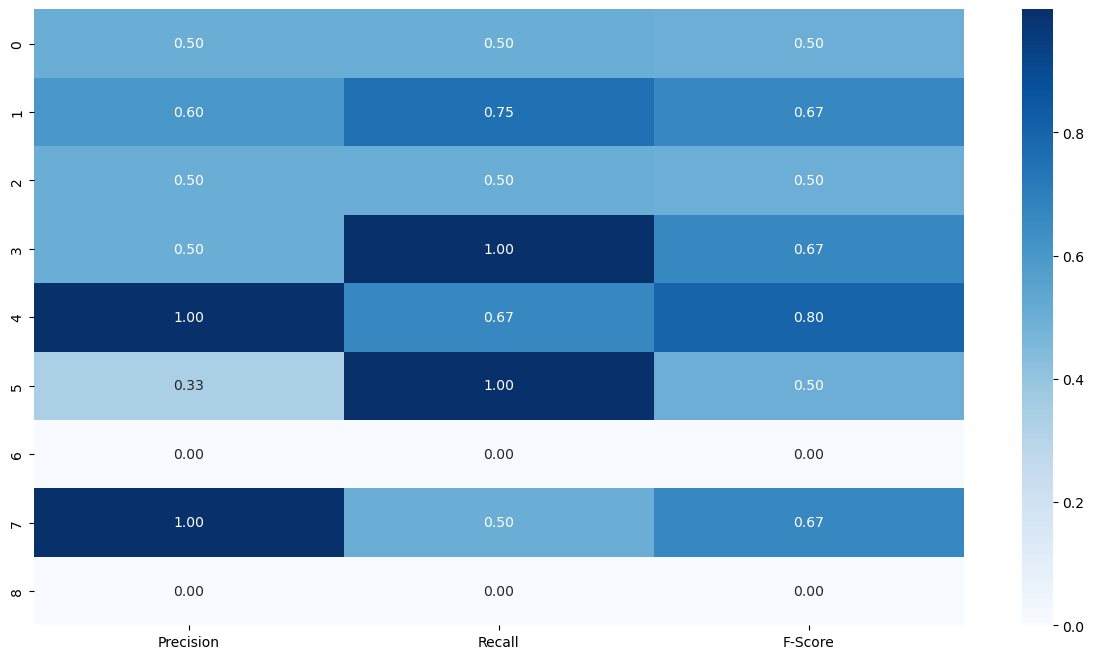

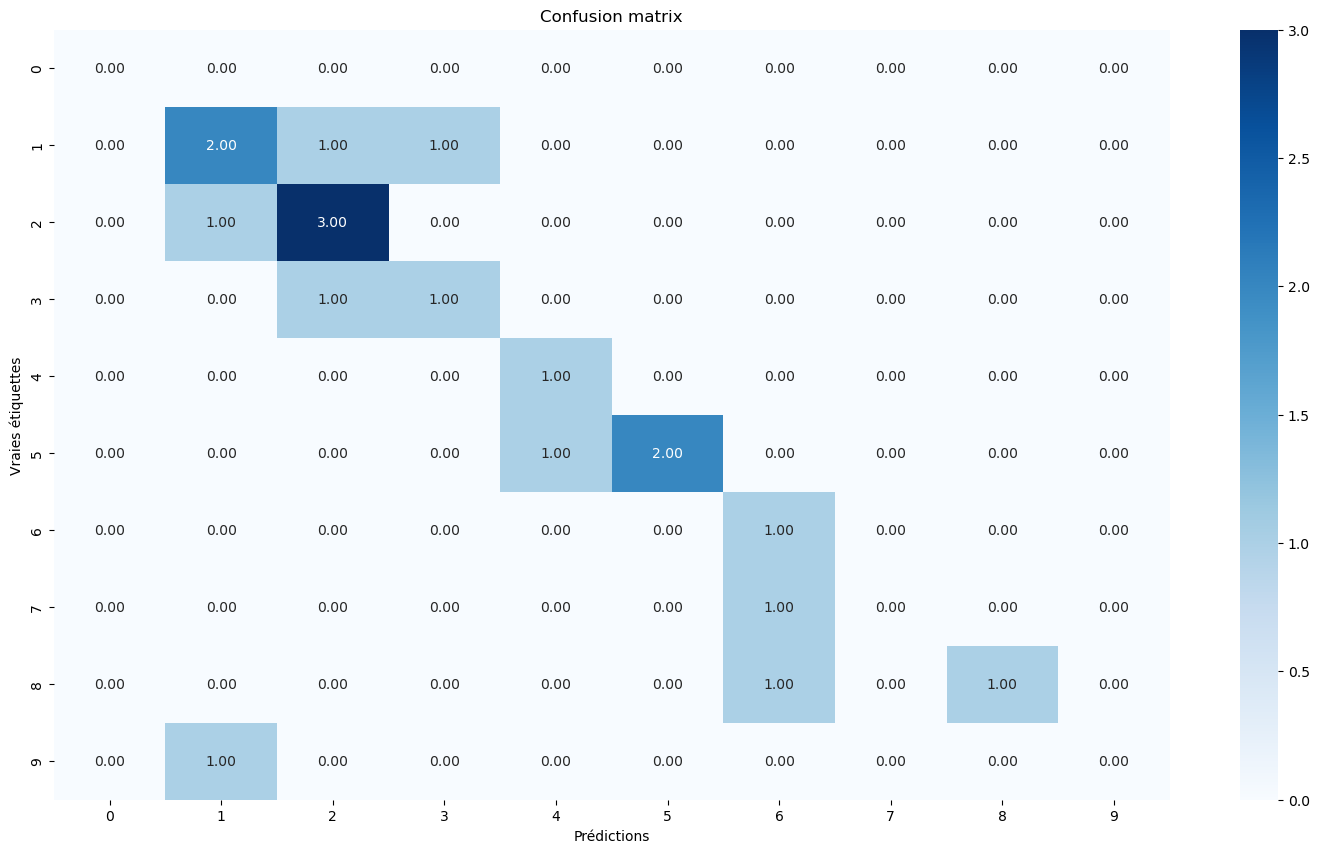

In [ ]:
from torchmetrics.classification import MulticlassF1Score, MulticlassConfusionMatrix

# Tensors
label = torch.Tensor([0, 1, 2, 3, 4, 5, 5, 5, 6, 7, 8, 8, 9, 0, 1, 2, 1, 2, 1, 2, 3])

preds = torch.Tensor([1, 1, 2, 3, 4, 5, 4, 5, 6, 6, 6, 8, 1, 8, 2, 2, 1, 2, 3, 1, 2])

#Torch metrics
cm = MulticlassConfusionMatrix(num_classes=10,ignore_index=0,normalize="none")
r_cm = cm(preds, label)

f = MulticlassF1Score(num_classes=10, ignore_index=0, average='macro')
r_f = f(preds, label)
#Homemade metrics
f_score = metrics.return_plot_f_score(r_cm.cpu())


fig_cm = metrics.convert_cm_to_figure(r_cm)
print(f"Tensor f-score = {r_f}")

In [15]:
r_f.mean()

tensor(0.4300)

In [6]:
print(metrics.calculate_miou(preds, label, n_classes=10))
print(metrics.calculate_kappa(r_cm))

0.3518517315387726
1.2999982450023693


In [11]:
alpha_weights = torch.from_numpy(
        np.load("./data_functions/alpha_weights.npy")
    ).float()

In [22]:
alpha_weights.std()

tensor(0.5223)

In [23]:
torch.nn.functional.softmax(alpha_weights, dim=0).std()

tensor(0.0288)

## Test models

In [20]:
UTAE_encoder = UTAE.UTAE(
    input_dim=10,
    encoder_widths=[32, 64, 128],
    decoder_widths=[64, 64, 128],
    out_conv=[32, 25],
    str_conv_k=4,
    str_conv_s=2,
    str_conv_p=1,
    agg_mode="att_group",
    encoder_norm="group",
    n_head=16,
    d_model=128,
    d_k=8,
    encoder=True,
    return_maps=False,
    pad_value=0,
    padding_mode="reflect",
)

LTAE_encoder = LTAE.LTAE2d(
    in_channels=10,
    n_head=16,
    d_k=8,
    d_model=128,
    T=1000,
    return_att=False,
    positional_encoding=True,
)

In [ ]:
inputs, y = next(iter(dl_train))
x = inputs[0]
dates = inputs[1]
geo = inputs[3]
out_utae = UTAE_encoder(x, dates)
out_ltae = LTAE_encoder(x, dates, mask)

In [8]:
print(out_utae.shape)
print(out_ltae.shape)

torch.Size([32768, 64])
torch.Size([32768, 128])


In [9]:
importlib.reload(lightning_module)

MLP_Decoder = utils_model.MLPDecoder(mlp=[64, 32, 25], dropout=0.2)

classifier = lightning_module.classifier(
    UTAE_encoder,
    MLP_Decoder,
    batch_size=batch_size,
    loss_fn=torch.nn.CrossEntropyLoss(
        weight=torch.from_numpy(np.load("./data_functions/alpha_weights.npy")).float(), ignore_index=0
    ),
    mask_need=False,
)
summary = ModelSummary(classifier, max_depth=-1)
print(summary)

    | Name                                                       | Type                      | Params | Mode  | FLOPs
---------------------------------------------------------------------------------------------------------------------------
0   | encoder                                                    | UTAE                      | 854 K  | train | 0    
1   | encoder.in_conv                                            | ConvBlock                 | 12.3 K | train | 0    
2   | encoder.in_conv.conv                                       | ConvLayer                 | 12.3 K | train | 0    
3   | encoder.in_conv.conv.conv                                  | Sequential                | 12.3 K | train | 0    
4   | encoder.in_conv.conv.conv.0                                | Conv2d                    | 2.9 K  | train | 0    
5   | encoder.in_conv.conv.conv.1                                | GroupNorm                 | 64     | train | 0    
6   | encoder.in_conv.conv.conv.2                 

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name           | Type                      | Params | Mode  | FLOPs
-----------------------------------------------------------------------------
0 | encoder        | UTAE                      | 854 K  | train | 0    
1 | decoder        | MLPDecoder                | 3.0 K  | train | 0    
2 | loss_fn        | CrossEntropyLoss          | 0      | train | 0    
3 | acc_metric     | MulticlassAccuracy        | 0      | train | 0    
4 | cm_metric      | MulticlassConfusionMatrix | 0 

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.


Testing: |          | 0/? [00:00<?, ?it/s]

[{}]

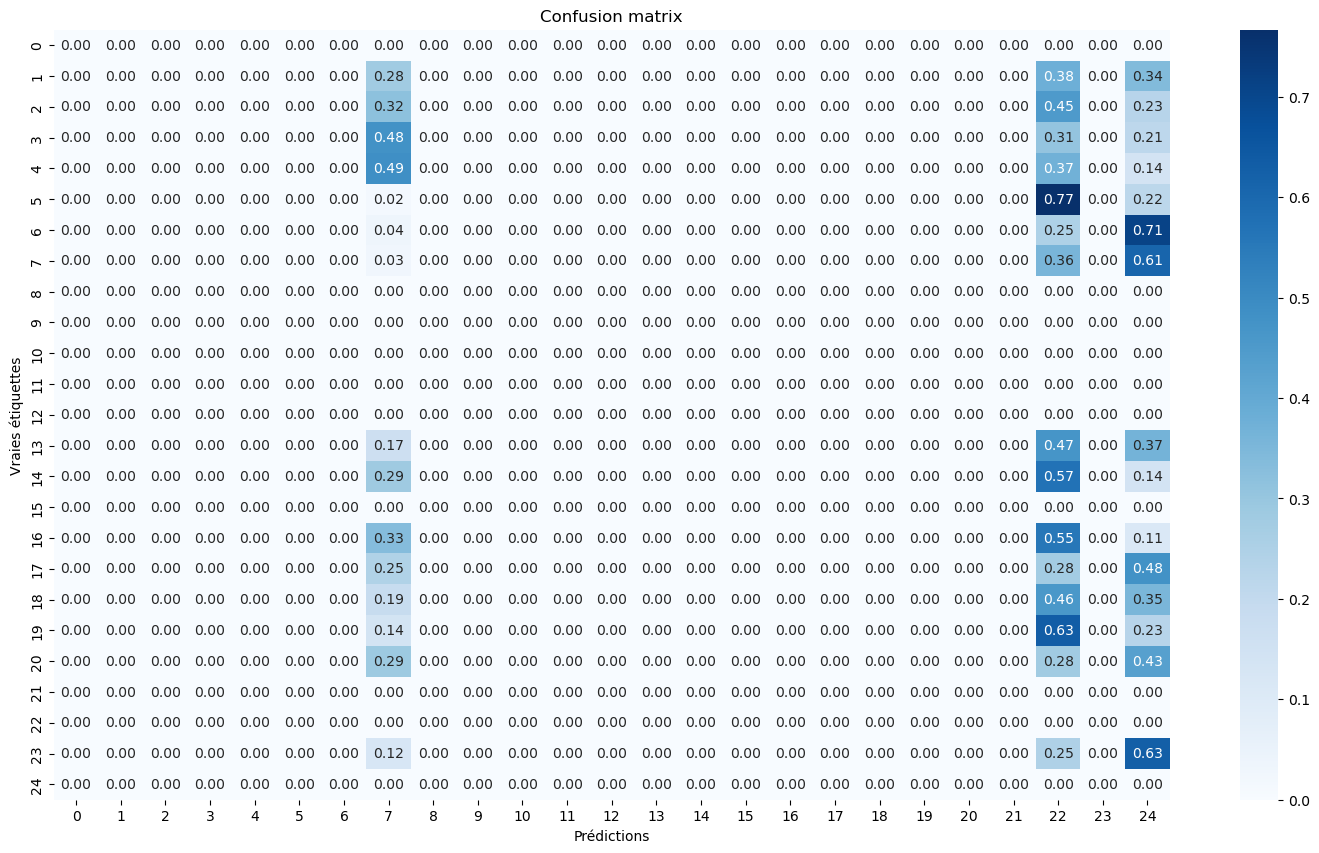

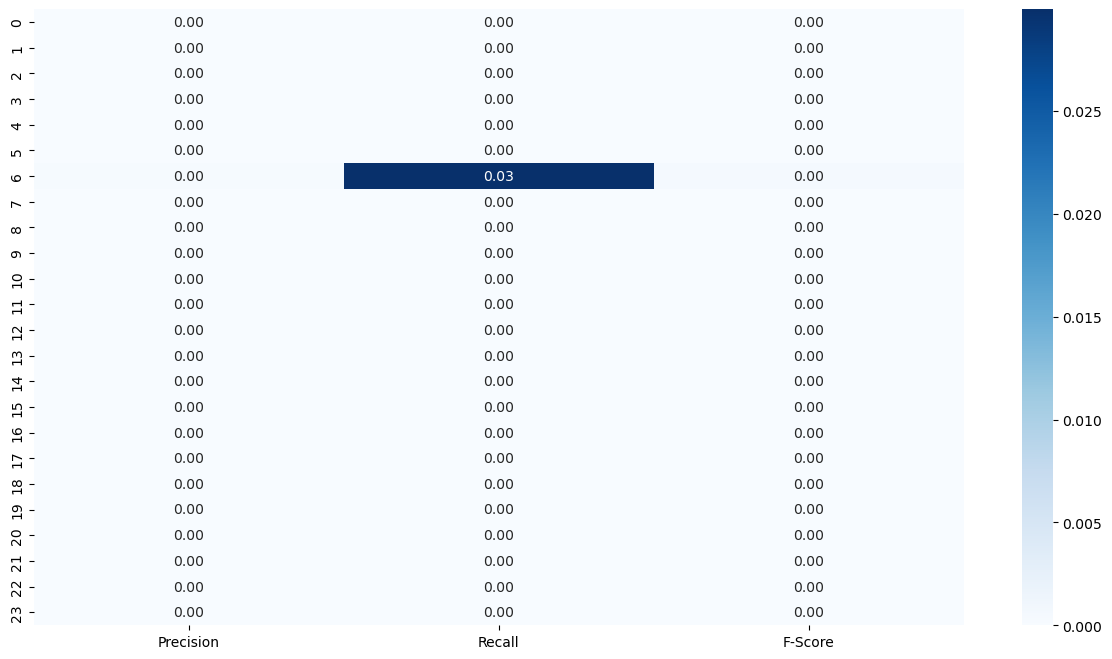

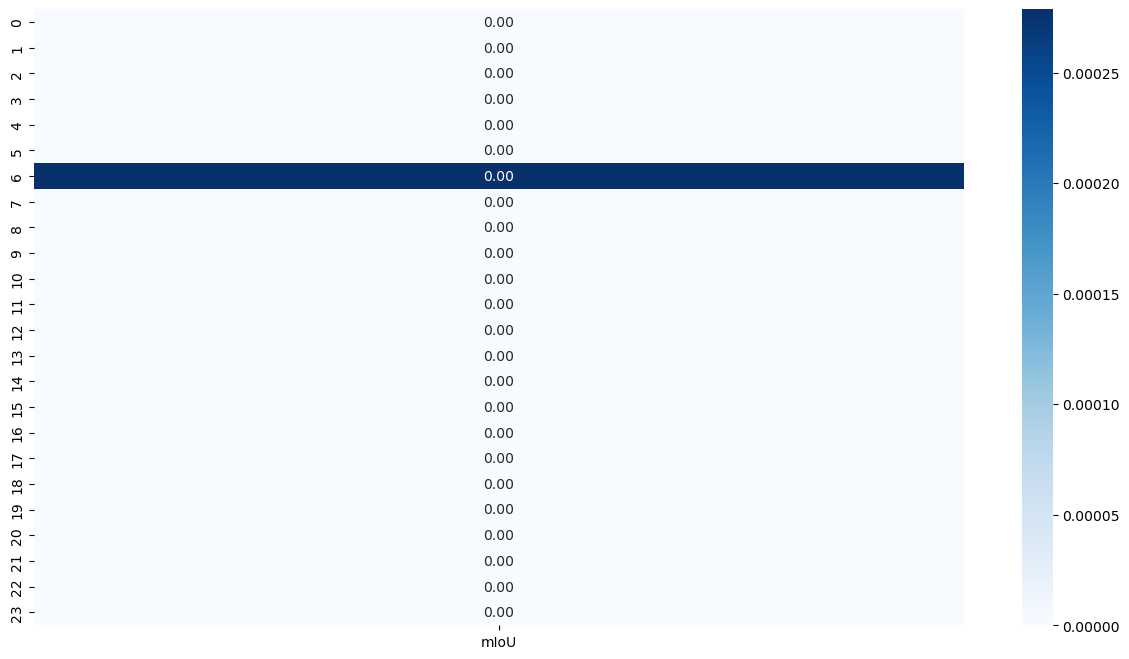

In [10]:
trainer = L.Trainer(
    max_epochs=1,
    profiler=False,
    logger=False,
    callbacks=[],
    limit_train_batches=2,
    limit_val_batches=2,
    limit_test_batches=2,
)
trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)

## Analyse model

In [3]:
LTAE_encoder = LTAE.LTAE2d(
    in_channels=10,
    n_head=16,
    d_k=8,
    d_model=128,
    T=1000,
    return_att=False,
    positional_encoding=True,
)
# Decoder
MLP_Decoder = utils_model.MLPDecoder(mlp=[128, 64, 25], dropout=0.2)

alpha_weights = torch.from_numpy(np.load("./data_functions/alpha_weights.npy"))
criterion_fl = metrics.FocalLoss(alpha=alpha_weights, gamma=2, ignore_index=0)

best_classifier = lightning_module.classifier.load_from_checkpoint(
    "/home/hkerino/Documents/next_oso/logs/light_training/LTAE_2026-03-04/Checkpoints/epoch=6-step=3745.ckpt",
    weights_only=True,
    encoder=LTAE_encoder,
    decoder=MLP_Decoder,
    loss_fn=criterion_fl,
    batch_size=4,
)

In [4]:
trainer = L.Trainer()
predictions = trainer.predict(best_classifier, dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

In [49]:
importlib.reload(utils_data)
y_true = []
x_img = []
for batch in dl_test:
    y_true.append(batch[1])
    x_img.append(utils_data.find_clear_img(batch))

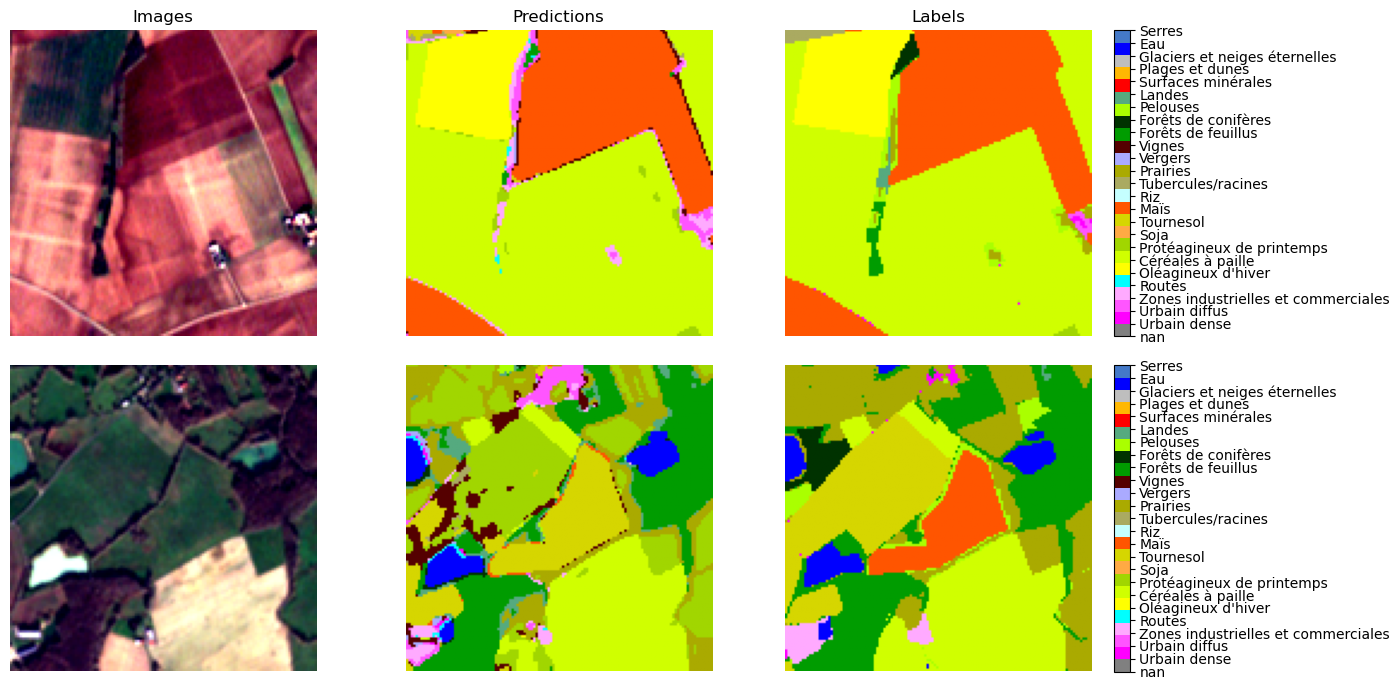

In [62]:
importlib.reload(utils_data)
fig = utils_data.plot_pred_label_and_img(
    preds=predictions, labels=y_true, imgs=x_img, batch_index=150
)


In [60]:
best_classifier = lightning_module.classifier(
    encoder=LTAE_encoder, decoder=MLP_Decoder, loss_fn=criterion_fl, batch_size=4
)
checkpoint = torch.load(
    "/home/hkerino/Documents/next_oso/logs/light_training/LTAE_2026-03-03/Checkpoints/epoch=6-step=3745.ckpt",
    map_location=torch.device("cpu"),
)
best_classifier.load_state_dict(checkpoint["state_dict"])

<All keys matched successfully>

In [58]:
trainer = L.Trainer()
trainer.test(model=best_classifier, dataloaders=dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Testing: |          | 0/? [00:00<?, ?it/s]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [55]:
dl_test.__iter__().__next__()


((tensor([[[[[ 3.6845e-01,  3.8038e-01,  3.7692e-01,  ...,  1.7315e-01,
               1.6866e-01,  1.8561e-01],
             [ 3.6706e-01,  3.6983e-01,  3.7658e-01,  ...,  1.8976e-01,
               1.8492e-01,  1.7160e-01],
             [ 3.6758e-01,  3.6620e-01,  3.9094e-01,  ...,  1.1988e-01,
               1.4513e-01,  1.7212e-01],
             ...,
             [ 4.2069e-01,  5.5181e-01,  7.4624e-01,  ...,  1.2109e-01,
               1.1399e-01,  1.2057e-01],
             [ 1.8855e-01,  2.6414e-01,  4.2847e-01,  ...,  1.4842e-01,
               1.3596e-01,  1.2316e-01],
             [ 1.6243e-01,  1.7298e-01,  2.2124e-01,  ...,  1.6762e-01,
               1.4859e-01,  1.3423e-01]],
  
            [[ 3.9388e-01,  4.0841e-01,  4.1619e-01,  ...,  2.1917e-01,
               2.2245e-01,  2.2020e-01],
             [ 3.8644e-01,  4.0097e-01,  4.0477e-01,  ...,  2.1000e-01,
               2.1052e-01,  2.0100e-01],
             [ 3.9768e-01,  3.8540e-01,  3.9889e-01,  ...,  1.9184e-01,
  

In [61]:
fc1_k_weights = best_classifier.encoder.attention_heads.fc1_k.weight
#fc1_k_weights = random_classifier.encoder.attention_heads.fc1_k.weight

fc1_k_bias = best_classifier.encoder.attention_heads.fc1_k.bias
#fc1_k_bias = random_classifier.encoder.attention_heads.fc1_k.bias

In [62]:
print("Moyenne des poids de fc1_k :", fc1_k_weights.mean().item())
print("Écart-type des poids de fc1_k :", fc1_k_weights.std().item())
print("Valeur minimale des poids de fc1_k :", fc1_k_weights.min().item())
print("Valeur maximale des poids de fc1_k :", fc1_k_weights.max().item())

Moyenne des poids de fc1_k : 0.016803469508886337
Écart-type des poids de fc1_k : 0.5966291427612305
Valeur minimale des poids de fc1_k : -3.7002270221710205
Valeur maximale des poids de fc1_k : 2.963665008544922


In [28]:
print(fc1_k_bias)

Parameter containing:
tensor([-0.2826, -0.1316,  0.0521, -0.3401,  0.1092,  0.3569, -0.3623,  0.1847,
         1.5921, -1.4384, -0.7386, -1.7028, -2.0471,  1.9382, -1.9020,  0.6456,
        -2.0057,  1.6865, -0.9347,  0.3112, -1.4652, -0.2113,  1.9350, -0.6870,
        -0.0525, -3.8446,  2.8255,  1.2033, -2.0300, -4.0744, -0.8235, -2.0647,
        -0.8368, -0.4018,  0.3518,  0.5308, -0.0392, -0.3034,  0.5065,  0.7947,
        -1.6013, -1.4035,  1.5157,  1.8127, -1.2580, -2.2166, -0.7960,  1.9608,
         0.5530, -0.0909,  0.3758,  0.6923, -0.0332, -0.1482,  0.1334, -0.7501,
        -0.9837,  0.6427, -0.4173,  0.9459,  1.0377,  0.7341,  0.5715, -0.3359,
         1.2623, -1.2669, -0.6346,  0.5100,  0.9105,  0.1857, -1.0379,  1.4316,
         0.1250,  0.8253,  0.6509, -0.7522, -0.4780, -0.0222, -0.7735,  0.1540,
        -0.2854,  0.8283, -0.2603,  0.1393, -0.3494, -0.8944, -0.3861,  0.1871,
         0.1988, -0.7142,  0.8770,  0.5687,  0.6903, -0.2376, -0.0598, -0.2229,
        -0.5406, -

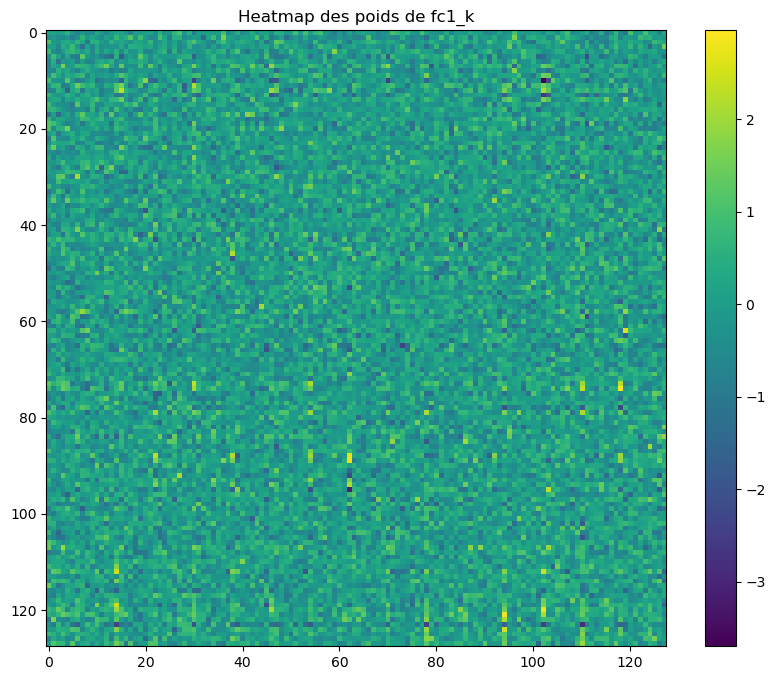

In [22]:
# Heatmap des poids de fc1_k
plt.figure(figsize=(10, 8))
plt.imshow(fc1_k_weights.detach().numpy(), cmap="viridis", aspect="auto")
plt.colorbar()
plt.title("Heatmap des poids de fc1_k")
plt.show()

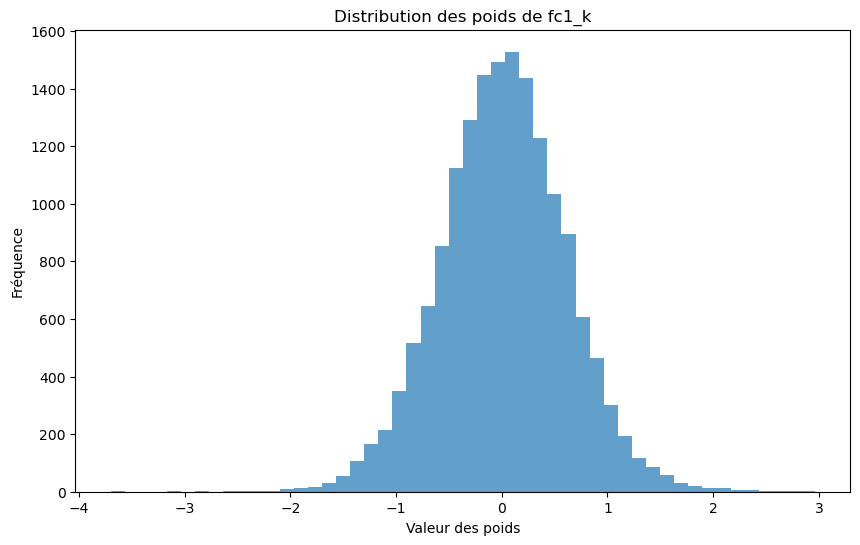

In [63]:
# Histogramme des poids de fc1_k
plt.figure(figsize=(10, 6))
plt.hist(fc1_k_weights.detach().numpy().flatten(), bins=50, alpha=0.7)
plt.title("Distribution des poids de fc1_k")
plt.xlabel("Valeur des poids")
plt.ylabel("Fréquence")
plt.show()

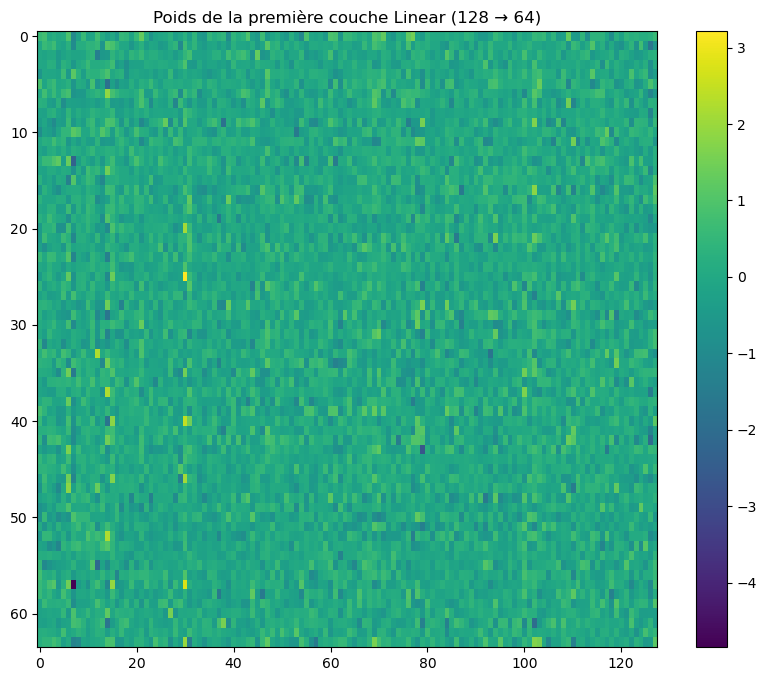

In [37]:
# Visualiser les poids de la première couche Linear
mlp = random_classifier.decoder.mlp
weights = mlp[0].weight.detach().numpy()  # Couche 0 : Linear(128, 64)
plt.figure(figsize=(10, 8))
plt.imshow(weights, cmap="viridis", aspect="auto")
plt.colorbar()
plt.title("Poids de la première couche Linear (128 → 64)")
plt.show()


In [ ]:
checkpoint = torch.load(
    "/home/hkerino/Documents/next_oso/logs/light_training/LTAE_2026-03-03/Checkpoints/epoch=6-step=3745.ckpt",
    map_location=torch.device("cpu"),
)
print("Clés dans le checkpoint :", checkpoint.keys())

# Vérifie que 'state_dict' est présent et contient les poids
if "state_dict" in checkpoint:
    print("Clés dans state_dict :", checkpoint["state_dict"].keys())
    fc1 = checkpoint["state_dict"]["encoder.attention_heads.fc1_k.weight"],

Clés dans le checkpoint : dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'hparams_name', 'hyper_parameters'])
Clés dans state_dict : odict_keys(['encoder.inconv.weight', 'encoder.inconv.bias', 'encoder.attention_heads.Q', 'encoder.attention_heads.fc1_k.weight', 'encoder.attention_heads.fc1_k.bias', 'decoder.mlp.0.weight', 'decoder.mlp.0.bias', 'decoder.mlp.1.weight', 'decoder.mlp.1.bias', 'decoder.mlp.1.running_mean', 'decoder.mlp.1.running_var', 'decoder.mlp.1.num_batches_tracked', 'decoder.mlp.3.weight', 'decoder.mlp.3.bias'])


In [48]:
fc1[0]

tensor([[ 1.6385e-01,  1.5985e-01, -1.8974e-04,  ...,  1.4583e-01,
         -7.1632e-01,  3.0195e-01],
        [-3.7844e-01, -4.8738e-02, -4.0001e-01,  ..., -1.5123e-01,
          5.9537e-02, -2.3376e-01],
        [ 1.1049e+00, -1.2472e-01, -1.9783e-01,  ...,  8.0589e-01,
          4.6742e-01,  2.3539e-01],
        ...,
        [ 7.4456e-01,  5.3159e-01,  9.5366e-02,  ..., -5.0816e-01,
          3.8559e-01, -2.5241e-01],
        [-7.3246e-01,  3.6314e-01, -1.0347e-01,  ...,  1.5674e+00,
          1.8340e-01,  1.2313e-02],
        [ 1.6181e-02,  1.1768e+00,  7.3047e-01,  ...,  3.1869e-01,
         -8.2166e-01, -1.6167e-01]])

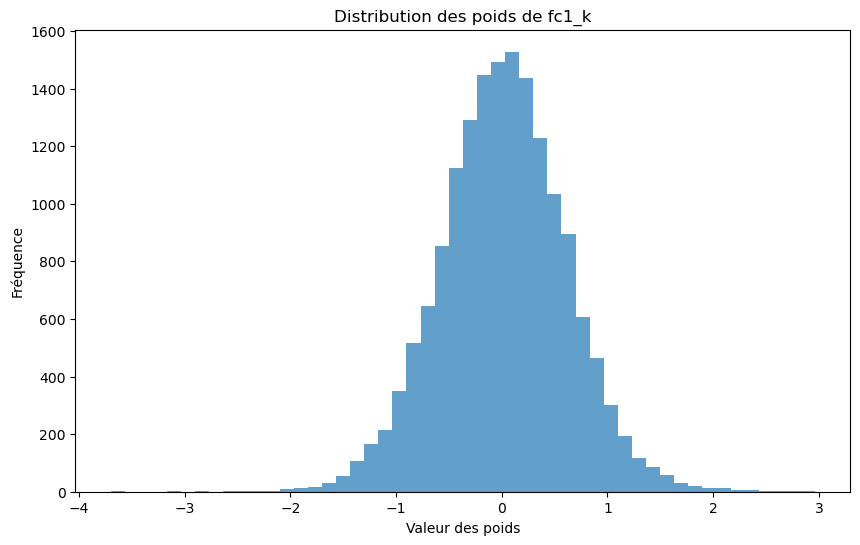

In [49]:
# Histogramme des poids de fc1_k
plt.figure(figsize=(10, 6))
plt.hist(fc1[0].detach().numpy().flatten(), bins=50, alpha=0.7)
plt.title("Distribution des poids de fc1_k")
plt.xlabel("Valeur des poids")
plt.ylabel("Fréquence")
plt.show()


In [50]:
fc1[0] == fc1_k_weights

tensor([[True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        ...,
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True],
        [True, True, True,  ..., True, True, True]])

## Test RF

In [73]:
from sklearn.ensemble import RandomForestClassifier

batch_size_RF = 20

dl_train_RF, dl_val_RF, dl_test_RF = dataset.get_loaders(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    folds_train=[1],
    folds_val=[4],
    folds_test=[5],
    batch_size=batch_size_RF,
    num_worker=4,
    norm=True,
    shuffle=True,
)

(x, dates, mask), y = dl_train_RF.__iter__().__next__()
print(x.shape)
print(dates.shape)
print(mask.shape)
print(y.shape)

torch.Size([20, 10, 79, 128, 128])
torch.Size([20, 79])
torch.Size([20, 79, 128, 128])
torch.Size([20, 128, 128])


In [74]:
clc = RandomForestClassifier()
clc.fit(x, y)

ValueError: Found array with dim 5, while dim <= 2 is required by RandomForestClassifier.

## Test loss functions

In [3]:
importlib.reload(metrics)
labels = torch.rand((4, 25, 128, 128))
labels = labels / labels.sum(dim=1, keepdim=True)

# Convertir labels en logits parfaits
predictions = torch.log(labels+1e-8)

threshold = np.random.rand(25)

#predictions = torch.log(labels.clamp(min=1e-10))

print(metrics.WeightedCE()(predictions, labels))
print(metrics.Hard_and_softCE()(predictions, labels))
print(metrics.MaskCE(thresholds=threshold)(predictions, labels))
print(metrics.DistillationLoss()(predictions, labels))

tensor(0.1786)
tensor(2.7934)
tensor(2.5431)
tensor(1.2824)


/home/hkerino/Documents/next_oso/src/metrics.py:363: UserWarning: reduction: 'mean' divides the total loss by both the batch size and the support size.'batchmean' divides only by the batch size, and aligns with the KL div math definition.'mean' will be changed to behave the same as 'batchmean' in the next major release.
  soft_loss = F.kl_div(log_probs, targets, reduction="mean") * self.T**2


In [5]:
probs, max = labels.max(dim=1)

In [12]:
probs[0]

tensor([[0.0724, 0.0707, 0.0659,  ..., 0.0789, 0.0774, 0.0706],
        [0.0730, 0.0830, 0.0708,  ..., 0.0781, 0.0717, 0.0779],
        [0.0854, 0.0631, 0.0673,  ..., 0.0912, 0.0733, 0.0719],
        ...,
        [0.0733, 0.0743, 0.0691,  ..., 0.0798, 0.0714, 0.0891],
        [0.0759, 0.0804, 0.0693,  ..., 0.0886, 0.0857, 0.0752],
        [0.0695, 0.0621, 0.0832,  ..., 0.0747, 0.0713, 0.0659]])

In [39]:
labels = torch.zeros((4, 25, 128, 128))
labels[:, 0, :, :] = 1.0  # one-hot parfaite

pred_logits = torch.zeros((4, 25, 128, 128))
pred_logits[:, 0, :, :] = 10.0

print(metrics.WeightedCE()(pred_logits, labels))
print(metrics.Hard_and_softCE(ignore_index=-100)(pred_logits, labels))
print(metrics.MaskCE(thresholds=threshold, ignore_index=-100)(pred_logits, labels))
print(metrics.DistillationLoss(ignore_index=-100)(pred_logits, labels))

tensor(0.0011)
tensor(0.0011)
tensor(0.0011)
tensor(0.0125)


In [40]:
threshold.shape

(25,)

## Pre-trainned ALISE


In [74]:
import onnxruntime
from Alise.utils_ALISE import ONNXEncoderWrapper, MLP_on_time_features

session = onnxruntime.InferenceSession(
    "/home/hkerino/Documents/model_data/alise_weights.onnx",
    providers=["CPUExecutionProvider"],
)

In [75]:
inputs, y = next(iter(dl_train))
print(inputs[0].shape)
print(inputs[1].shape)

x = rearrange(inputs[0], 'b c t h w -> b t h w c')
dates = inputs[1]

torch.Size([2, 10, 75, 128, 128])
torch.Size([2, 75])


In [76]:
input_1 = {
    "sits": x.numpy(),
    "tpe": dates.float().numpy(),
    "padd_mask": torch.zeros(dates.shape).bool().numpy(),
}

out_ort = session.run(None ,input_1)[0]

In [8]:
print(out_ort.shape)

(2, 10, 64, 128, 128)


In [9]:
encoder = ONNXEncoderWrapper(session=session)
out_enc = encoder(inputs[0], inputs[1])

In [12]:
print(out_enc.shape)

torch.Size([32768, 10, 64])


In [ ]:
decoder = MLP_on_time_features(mlp = [640,320,100, 50,25])

In [14]:
decoder(out_enc).shape

torch.Size([32768, 25])

In [10]:
import onnx 

PATH_TO_ONNX = "/home/hkerino/Documents/model_data/alise_weights.onnx"
onnx_model = onnx.load(PATH_TO_ONNX)

weights = {}

for tensor in onnx_model.graph.initializer:
    name = tensor.name
    array = onnx.numpy_helper.to_array(tensor)
    weights[name] = array

print(weights.keys())
print(len(weights))

dict_keys(['repr_encoder.ubarn.temporal_encoder.layer_stack.0.attn.mha.out_proj.weight', 'repr_encoder.ubarn.temporal_encoder.layer_stack.0.attn.mha.out_proj.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.0.conv_block.block.linear1.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.0.conv_block.block.linear2.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.0.norm.weight', 'repr_encoder.ubarn.temporal_encoder.layer_stack.0.norm.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.1.attn.mha.out_proj.weight', 'repr_encoder.ubarn.temporal_encoder.layer_stack.1.attn.mha.out_proj.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.1.conv_block.block.linear1.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.1.conv_block.block.linear2.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.1.norm.weight', 'repr_encoder.ubarn.temporal_encoder.layer_stack.1.norm.bias', 'repr_encoder.ubarn.temporal_encoder.layer_stack.2.attn.mha.out_proj.weight', 'repr_encoder.u

In [28]:
d = dataset.next_oso_Dataset(
        path_s2=PATH_TO_DATA_s2,
        path_mnt=PATH_MNT,
        path_label=PATH_TO_DATA_label,
        path_oso_class=PATH_TO_OSO_CLASSES,
        folds=1,
        norm=False,
        norm_pretrained_alise=True,
        mask_needed=False,
        use_spatial_coords=False,
        return_id=True,
    )
print(d.__len__())

TypeError: 'int' object is not iterable

In [22]:
(s2,dates,_,_), label, id = d.__getitem__(2)

In [23]:
id

'0045'

In [5]:
from Alise import utils_ALISE
import onnxruntime as ort

PATH_TO_ONNX = "/home/hkerino/Documents/model_data/alise_weights.onnx"
session = ort.InferenceSession(
    PATH_TO_ONNX, providers=["CUDAExecutionProvider", "CPUExecutionProvider"]
)

alise = utils_ALISE.ONNXEncoderWrapper(session)
alise_out = alise(s2.unsqueeze(0), dates.unsqueeze(0))

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/onnxruntime/capi/onnxruntime_inference_collection.py:123: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'CPUExecutionProvider'
  warnings.warn(


In [8]:
alise_out

[array([[[[[ 3.55270356e-01,  5.85626066e-01,  5.94539940e-01, ...,
             5.96658945e-01,  5.69196761e-01,  6.29744828e-01],
           [ 5.71227431e-01,  6.59851789e-01,  6.22439265e-01, ...,
             5.82634687e-01,  5.61700642e-01,  6.05032265e-01],
           [ 6.45852625e-01,  6.52787566e-01,  5.73938549e-01, ...,
             5.86325288e-01,  5.57732463e-01,  5.90943158e-01],
           ...,
           [ 3.40762854e-01,  3.65416765e-01,  3.37932944e-01, ...,
             4.30238783e-01,  3.66642445e-01,  4.04642880e-01],
           [ 3.47219020e-01,  3.75193119e-01,  3.45352471e-01, ...,
             4.49962616e-01,  4.39437032e-01,  5.03331184e-01],
           [ 3.40926319e-01,  3.81335258e-01,  3.33253771e-01, ...,
             4.56049263e-01,  4.47958589e-01,  5.12983739e-01]],
 
          [[ 3.84961247e-01,  8.89704973e-02,  2.34418362e-02, ...,
             1.76771879e-01,  2.28794724e-01,  2.12178096e-01],
           [ 1.14250250e-01,  7.24367797e-03,  2.88131833

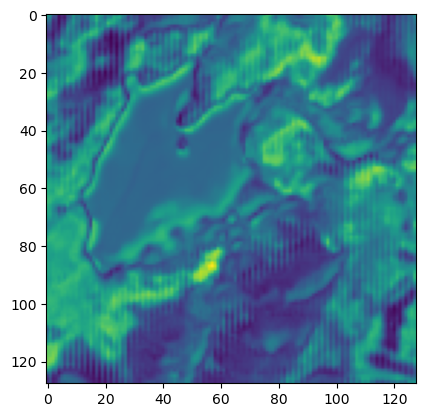

In [24]:
plt.imshow(torch.load("/home/hkerino/Documents/model_data/embeddings/0045.pt")[2,1,:,:])

In [17]:
s2.shape

torch.Size([10, 30, 128, 128])

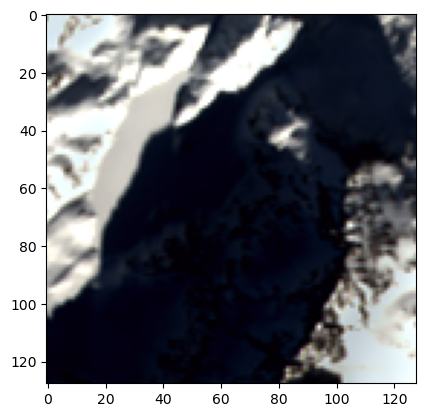

In [25]:
plt.imshow(utils_data.to_RGB(s2[:,0,:,:]))

## S2 variables

In [5]:
s2 = xr.open_dataset(
    "/home/hkerino/Documents/nextoso-dataset/data/10m/s2/1/fold_1/s2_0002.nc"
)

In [7]:
s2['x']
s2['y']

<xarray.DataArray 'y' (y: 128)> Size: 512B
array([6.194116e+06, 6.194106e+06, 6.194096e+06, 6.194086e+06, 6.194076e+06,
       6.194066e+06, 6.194056e+06, 6.194046e+06, 6.194036e+06, 6.194026e+06,
       6.194016e+06, 6.194006e+06, 6.193996e+06, 6.193986e+06, 6.193976e+06,
       6.193966e+06, 6.193956e+06, 6.193946e+06, 6.193936e+06, 6.193926e+06,
       6.193916e+06, 6.193906e+06, 6.193896e+06, 6.193886e+06, 6.193876e+06,
       6.193866e+06, 6.193856e+06, 6.193846e+06, 6.193836e+06, 6.193826e+06,
       6.193816e+06, 6.193806e+06, 6.193796e+06, 6.193786e+06, 6.193776e+06,
       6.193766e+06, 6.193756e+06, 6.193746e+06, 6.193736e+06, 6.193726e+06,
       6.193716e+06, 6.193706e+06, 6.193696e+06, 6.193686e+06, 6.193676e+06,
       6.193666e+06, 6.193656e+06, 6.193646e+06, 6.193636e+06, 6.193626e+06,
       6.193616e+06, 6.193606e+06, 6.193596e+06, 6.193586e+06, 6.193576e+06,
       6.193566e+06, 6.193556e+06, 6.193546e+06, 6.193536e+06, 6.193526e+06,
       6.193516e+06, 6.193506e+06, 6.193496e+06, 6.193486e+06, 6.193476e+06,
       6.193466e+06, 6.193456e+06, 6.193446e+06, 6.193436e+06, 6.193426e+06,
       6.193416e+06, 6.193406e+06, 6.193396e+06, 6.193386e+06, 6.193376e+06,
       6.193366e+06, 6.193356e+06, 6.193346e+06, 6.193336e+06, 6.193326e+06,
       6.193316e+06, 6.193306e+06, 6.193296e+06, 6.193286e+06, 6.193276e+06,
       6.193266e+06, 6.193256e+06, 6.193246e+06, 6.193236e+06, 6.193226e+06,
       6.193216e+06, 6.193206e+06, 6.193196e+06, 6.193186e+06, 6.193176e+06,
       6.193166e+06, 6.193156e+06, 6.193146e+06, 6.193136e+06, 6.193126e+06,
       6.193116e+06, 6.193106e+06, 6.193096e+06, 6.193086e+06, 6.193076e+06,
       6.193066e+06, 6.193056e+06, 6.193046e+06, 6.193036e+06, 6.193026e+06,
       6.193016e+06, 6.193006e+06, 6.192996e+06, 6.192986e+06, 6.192976e+06,
       6.192966e+06, 6.192956e+06, 6.192946e+06, 6.192936e+06, 6.192926e+06,
       6.192916e+06, 6.192906e+06, 6.192896e+06, 6.192886e+06, 6.192876e+06,
       6.192866e+06, 6.192856e+06, 6.192846e+06], dtype=float32)
Coordinates:
  * y        (y) float32 512B 6.194e+06 6.194e+06 ... 6.193e+06 6.193e+06
Attributes:
    standard_name:  projection_y_coordinate
    long_name:      y coordinate of projection
    units:          m

## Positionnal Encoding

In [ ]:
from models.utils_model import PositionalEncoder, duplicate_to_img

In [93]:
date = torch.Tensor(np.arange(365*1)[None])

In [94]:
d_model = 256
n_head = 16
pe = PositionalEncoder(d=d_model // n_head, T=1000,repeat=n_head)(date)

In [95]:
pe.shape

torch.Size([1, 365, 256])

(np.float64(-0.5), np.float64(255.5), np.float64(364.5), np.float64(-0.5))

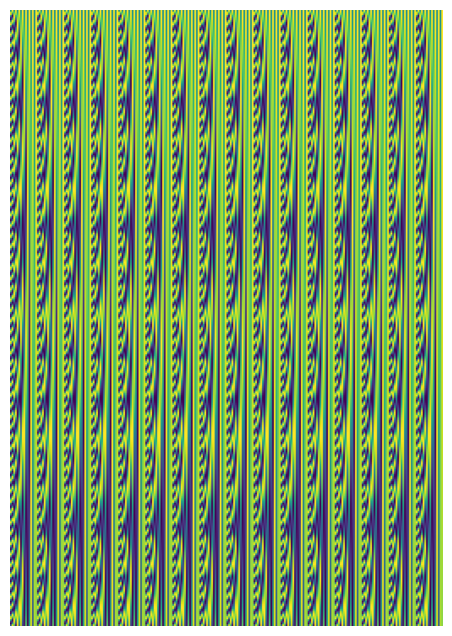

In [96]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(pe.squeeze())
ax.set_xlabel('Embedding dimension')
ax.set_ylabel('Dates')
ax.axis('off')

(np.float64(-0.5), np.float64(15.5), np.float64(364.5), np.float64(-0.5))

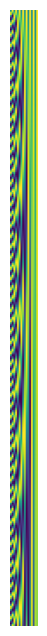

In [98]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(pe.squeeze()[:, : d_model // n_head])
ax.set_xlabel("Embedding dimension")
ax.set_ylabel("Dates")
ax.axis("off")

In [134]:
(x, dates, _ ), _ = next(iter(dl_train))

In [135]:
x.shape, dates.shape

(torch.Size([4, 10, 54, 128, 128]), torch.Size([4, 54]))

In [136]:
x_d_model = rearrange(x, 'b c t h w -> (b h w) c t')
out_d_model = nn.Conv1d(x_d_model.shape[1], d_model, 1)(x_d_model)
out_d_model = out_d_model.transpose(1, 2)
out_d_model.shape

torch.Size([65536, 54, 256])

In [137]:
dates_img = duplicate_to_img(dates)

In [139]:
pe = PositionalEncoder(d=d_model // n_head, T=1000,repeat=n_head)(dates_img)

In [141]:
out = out_d_model + pe 
out.shape

torch.Size([65536, 54, 256])

(np.float64(-0.5), np.float64(15.5), np.float64(53.5), np.float64(-0.5))

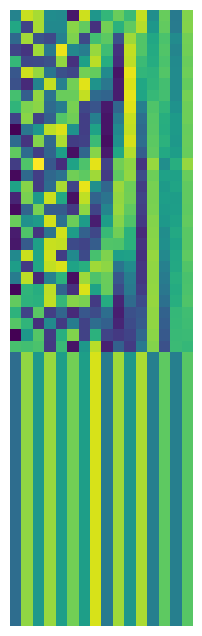

In [145]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(out[0,:,:n_head].detach().cpu().numpy())
ax.set_xlabel("Embedding dimension")
ax.set_ylabel("Dates")
ax.axis("off")

## MNT

In [26]:
id = '0148'
s2 = xr.open_dataset(
    f"/home/hkerino/Documents/nextoso-dataset/data/10m/s2/1/fold_1/s2_{id}.nc"
)
elev = np.load(f"/home/hkerino/Documents/nextoso-dataset/data/10m/mnt/elev/elev_{id}.npy")
slope = np.load(
    f"/home/hkerino/Documents/nextoso-dataset/data/10m/mnt/slope/slope_{id}.npy"
)
print(elev.shape)
print(slope.shape)

(128, 128)
(128, 128)


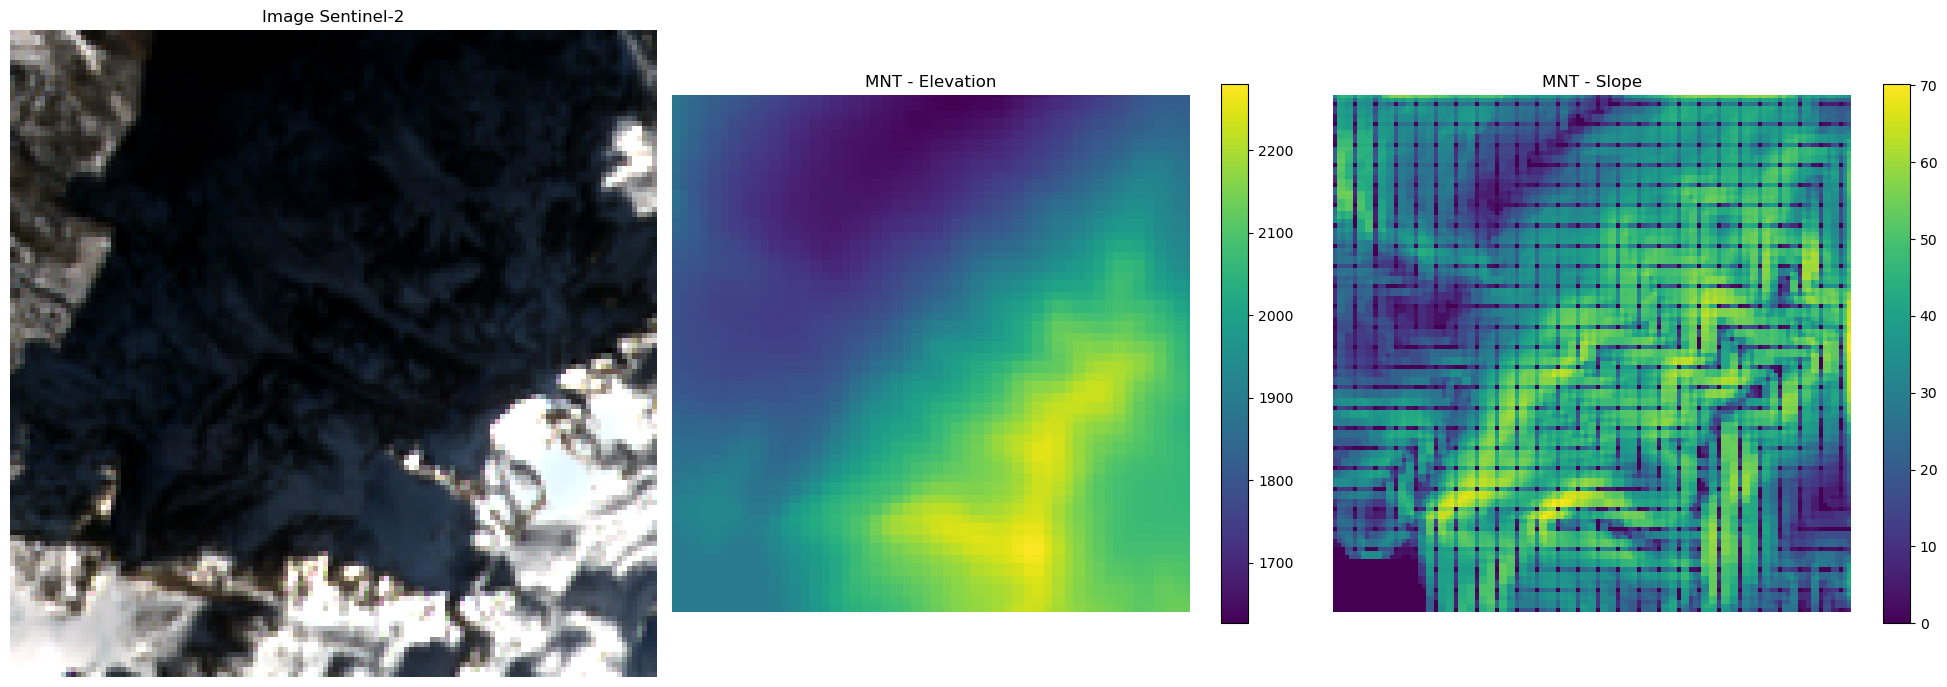

In [27]:
fig, ax = plt.subplots(nrows=1,ncols=3,figsize=(20, 8))
im0 = ax[0].imshow(utils_data.to_RGB(s2.isel(time=0)))
ax[0].set_title("Image Sentinel-2")
ax[0].axis("off")
im1 = ax[1].imshow(elev)
ax[1].set_title("MNT - Elevation")
ax[1].axis("off")
cbar1 = fig.colorbar(im1, ax=ax[1], shrink=0.7)
im2 = ax[2].imshow(slope)
ax[2].set_title("MNT - Slope")
ax[2].axis("off")
cbar2 = fig.colorbar(im2, ax=ax[2], shrink=0.7)

plt.tight_layout()
plt.show()

In [28]:
min_y, max_y = 6e6, 7.2e6
min_x, max_x = 1e5, 1.3e6

x_norm = (s2.x - min_x) / (max_x - min_x)
y_norm = (s2.y - min_y) / (max_y - min_y)

print(y_norm.values)
print(x_norm.values)

[0.14853875 0.14853042 0.14852208 0.14851375 0.14850542 0.14849709
 0.14848875 0.14848042 0.14847209 0.14846376 0.14845541 0.14844708
 0.14843875 0.14843042 0.14842208 0.14841375 0.14840542 0.14839709
 0.14838874 0.14838041 0.14837208 0.14836375 0.14835541 0.14834708
 0.14833875 0.14833042 0.14832209 0.14831375 0.14830542 0.14829709
 0.14828876 0.14828041 0.14827208 0.14826375 0.14825542 0.14824708
 0.14823875 0.14823042 0.14822209 0.14821374 0.14820541 0.14819708
 0.14818875 0.14818041 0.14817208 0.14816375 0.14815542 0.14814708
 0.14813875 0.14813042 0.14812209 0.14811376 0.14810541 0.14809708
 0.14808875 0.14808042 0.14807208 0.14806375 0.14805542 0.14804709
 0.14803874 0.14803042 0.14802209 0.14801376 0.14800541 0.14799708
 0.14798875 0.14798042 0.14797208 0.14796375 0.14795542 0.14794709
 0.14793874 0.14793041 0.14792208 0.14791375 0.14790541 0.14789708
 0.14788875 0.14788042 0.14787209 0.14786375 0.14785542 0.14784709
 0.14783876 0.14783041 0.14782208 0.14781375 0.14780542 0.1477

In [29]:
elev_max = 3000
slope_max = 90

elev_norm = elev / elev_max
slope_norm = slope / slope_max

print(elev_norm)

[[0.62766667 0.62766667 0.62266667 ... 0.605      0.605      0.60466667]
 [0.62566667 0.62566667 0.62033333 ... 0.60766667 0.60766667 0.607     ]
 [0.62566667 0.62566667 0.62033333 ... 0.60766667 0.60766667 0.607     ]
 ...
 [0.63166667 0.63166667 0.63166667 ... 0.70933333 0.70933333 0.70833333]
 [0.63166667 0.63166667 0.63166667 ... 0.711      0.711      0.71066667]
 [0.63166667 0.63166667 0.63166667 ... 0.711      0.711      0.71066667]]


In [30]:
print(slope_norm)

[[0.34404174 0.48716478 0.5081428  ... 0.42955343 0.43015891 0.39182655]
 [0.18554716 0.45011766 0.4569763  ... 0.24223788 0.24896524 0.24394443]
 [0.         0.42955343 0.42955343 ... 0.         0.06345103 0.12566592]
 ...
 [0.         0.         0.         ... 0.15595826 0.18059908 0.27498473]
 [0.         0.         0.         ... 0.15595826 0.15892127 0.22224204]
 [0.         0.         0.         ... 0.         0.0318045  0.06345103]]


In [31]:
importlib.reload(dataset)
importlib.reload(utils_data)
batch_size = 2

dl_train, dl_val, dl_test = dataset.get_loaders(
    path_s2=PATH_TO_DATA_s2,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    folds_train=[1],
    folds_val=[4],
    folds_test=[5],
    batch_size=batch_size,
    mask_needed=False,
    use_spatial_coords= True,
    num_worker=4,
    norm=True,
    shuffle=True,
    label_type="max_class",
)

In [32]:
len(next(iter(dl_train))[0])

3

In [33]:
(x,dates, geo), y = dl_train.__iter__().__next__()

In [38]:
rearrange(geo, "b c h w -> (b h w) c").shape

torch.Size([32768, 4])

In [ ]:
np.expand_dims(s2["x"].values, axis=1).repeat(128, axis=1)

array([582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 582233.5,
       582233.5, 582233.5, 582233.5, 582233.5, 582233.5, 58223

In [40]:
x = torch.randn(100, 4)
z = torch.randn(100, 32)

r = torch.cat([z, x], dim=1)
print(r.shape)

torch.Size([100, 36])


In [21]:
dl_train, dl_val, dl_test = dataset.get_loaders(
    path_s2=PATH_TO_DATA_s2,
    path_mnt=PATH_MNT,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    folds_train=[1],
    folds_val=[4],
    folds_test=[5],
    batch_size=batch_size,
    num_worker=4,
    norm=False,
    norm_alise=True,
    shuffle=True,
    label_type="max_class",
    use_spatial_coords=True,
    mask_needed=False,
    sequence_packing=False,
    pass_id=False,
)

inputs, y = next(iter(dl_train))
print(inputs[0].shape)
print(inputs[1].shape)
print(inputs[2].shape)
print(y.shape)

torch.Size([2, 10, 48, 128, 128])
torch.Size([2, 48])
torch.Size([2, 4, 128, 128])
torch.Size([2, 128, 128])


In [ ]:
UTAE_encoder = UTAE.UTAE(
    input_dim=10,
    encoder_widths=[32, 64, 128],
    decoder_widths=[64, 64, 128],
    out_conv=[32, 25],
    str_conv_k=4,
    str_conv_s=2,
    str_conv_p=1,
    agg_mode="att_group",
    encoder_norm="group",
    n_head=16,
    d_model=128,
    d_k=8,
    encoder=True,
    return_maps=False,
    pad_value=0,
    padding_mode="reflect",
)

MLP_Decoder = utils_model.MLPDecoder(mlp=[64, 32, 25], dropout=0.2)

classifier = lightning_module.classifier(
    UTAE_encoder,
    MLP_Decoder,
    batch_size=batch_size,
    loss_fn=torch.nn.CrossEntropyLoss(
        weight=torch.from_numpy(np.load("./data_functions/alpha_weights.npy")).float(),
        ignore_index=0,
    ),
    mask_need=False,
)
summary = ModelSummary(classifier, max_depth=-1)
print(summary)

## Normalisation

In [39]:
import torch
import torchvision
from einops import rearrange
import pandas as pd
from dataclasses import dataclass
from torch import Tensor

@dataclass
class Stats:
    """
    Store stats
    """

    median: list
    qmin: list
    qmax: list


@dataclass
class OneTransform:
    """
    Store transform and its associated stats
    """

    transform: torch.nn.Module | None = None
    stats: Stats | None = None


def read_csv_stat(path_csv) -> Stats:
    """
    Read the stats stored in a casv
    Parameters
    ----------
    path_csv :

    Returns
    -------

    """
    df_stats = pd.read_csv(path_csv, sep=",", index_col=0)
    return Stats(
        median=df_stats.loc(axis=1)["median"].tolist(),
        qmin=df_stats.loc(axis=1)["p_min"].tolist(),
        qmax=df_stats.loc(axis=1)["p_max"].tolist(),
    )

class Clip(torch.nn.Module):
    """
    Clip transform for data, clip each band between two values qmin and qmax
    """

    def __init__(self, qmin: list, qmax: list, s2_partial: bool = False):
        super().__init__()

        self.qmin = rearrange(
            torch.Tensor(qmin), "c -> c 1 1 1"
        )  # reshape so that it is broadcastable
        self.qmax = rearrange(torch.Tensor(qmax), "c ->  c  1 1 1 ")
        self.s2_partial = s2_partial

    def forward(self, tensor: torch.Tensor) -> torch.Tensor:
        tmp_tensor = tensor
        assert len(tensor.shape) == 4
        qmax = self.qmax.to(tmp_tensor)
        qmin = self.qmin.to(tmp_tensor)
        tmp_tensor[torch.isnan(tmp_tensor)] = torch.max(qmax) + 100
        tmp_tensor = torch.min(
            torch.max(tmp_tensor, qmin), qmax
        )  # clip values on the quantile

        return tmp_tensor

    def __repr__(self):
        return self.__class__.__name__ + "( qmin={} , qmax={})".format(
            self.qmin, self.qmax
        )


class S2Normalize(torch.nn.Module):
    """Robust Normalization"""

    def __init__(
        self,
        med: list | tuple,
        scale: list | tuple,
    ):
        super().__init__()
        self.med = med  # reshape so that it is broadcastable
        self.scale = scale
        self.transform = torchvision.transforms.Normalize(mean=med, std=scale)

    def forward(self, tensor: torch.Tensor):
        tensor = rearrange(tensor, "c t h w -> t c h w").to(torch.float)
        tensor = self.transform(tensor)
        return rearrange(tensor, "t c h w -> c t h w")

    def __repr__(self):
        return self.__class__.__name__ + "( med={} , scale={})".format(
            self.med, self.scale
        )

def load_transform_one_mod(path_dir_csv: str, mod: str = "s2") -> OneTransform:
    """

    Parameters
    ----------
    path_dir_csv : path where norms are stored
    mod : modality, implemented only of S2

    Returns
    -------

    """
    if mod != "s2":
        raise NotImplementedError
    
    stats = read_csv_stat(path_dir_csv)
    scale = tuple([float(x) - float(y) for x, y in zip(stats.qmax, stats.qmin)])
    return OneTransform(
        torch.nn.Sequential(
            Clip(qmin=stats.qmin, qmax=stats.qmax),
            S2Normalize(med=stats.median, scale=scale),
        ),
        stats,
    )


In [40]:
stats = read_csv_stat("/home/hkerino/Documents/nextoso-dataset/data/10m/s2/stats.csv")
print(stats)

Stats(median=[376.0, 631.0, 592.0, 1057.0, 2273.0, 2622.0, 2725.0, 2920.0, 1907.0, 1099.0], qmin=[1.0, 81.0, 3.0, 201.0, 516.0, 614.0, 575.0, 687.0, 336.0, 195.0], qmax=[5650.0, 5634.0, 5779.0, 5847.0, 6130.0, 6226.0, 6223.0, 6334.0, 4648.0, 3688.0])


In [41]:
scale = tuple([float(x) - float(y) for x, y in zip(stats.qmax, stats.qmin)])
print(scale)
print(stats.median)
clip_ = Clip(qmin=stats.qmin, qmax=stats.qmax)
norm_ = S2Normalize(med=stats.median, scale=scale)
test_transform = torch.nn.Sequential(
    clip_,
    norm_
)

(5649.0, 5553.0, 5776.0, 5646.0, 5614.0, 5612.0, 5648.0, 5647.0, 4312.0, 3493.0)
[376.0, 631.0, 592.0, 1057.0, 2273.0, 2622.0, 2725.0, 2920.0, 1907.0, 1099.0]


In [42]:
from data_functions import transfrom
s2 = xr.open_dataset(
    "/home/hkerino/Documents/nextoso-dataset/data/10m/s2/2/fold_1/s2_0010.nc"
)
s2_ = utils_data.remove_invalid(s2)
s2_array = (
                s2_[["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]]
                .to_dataarray()
                .to_numpy()
            )
s2_tensor = torch.from_numpy(s2_array).float()

normalization = load_transform_one_mod(
    path_dir_csv="/home/hkerino/Documents/nextoso-dataset/data/10m/s2/stats.csv",
    mod="s2",
)

s2_norm = normalization.transform(s2_tensor)

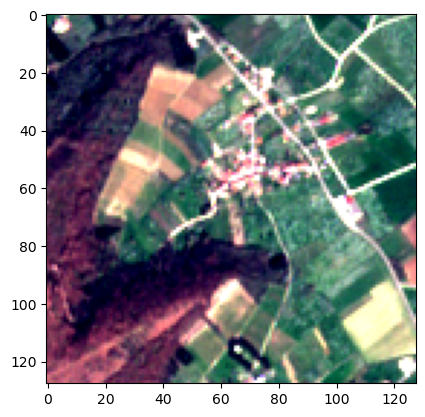

In [31]:
plt.imshow(utils_data.to_RGB(s2_norm[:, 3, :, :]))

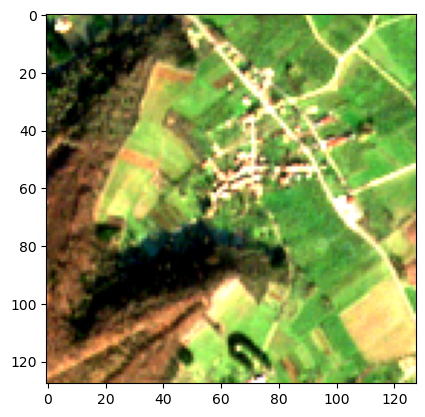

In [32]:
plt.imshow(utils_data.to_RGB(s2_tensor[:, 0, :, :]))

In [43]:
dt.transform_norm.stats

Stats(median=[376.0, 631.0, 592.0, 1057.0, 2273.0, 2622.0, 2725.0, 2920.0, 1907.0, 1099.0], qmin=[1.0, 81.0, 3.0, 201.0, 516.0, 614.0, 575.0, 687.0, 336.0, 195.0], qmax=[5650.0, 5634.0, 5779.0, 5847.0, 6130.0, 6226.0, 6223.0, 6334.0, 4648.0, 3688.0])

In [22]:
s2_tensor- stats.median

TypeError: unsupported operand type(s) for -: 'Tensor' and 'list'

In [47]:
inputs, labels = next(iter(dl_train))

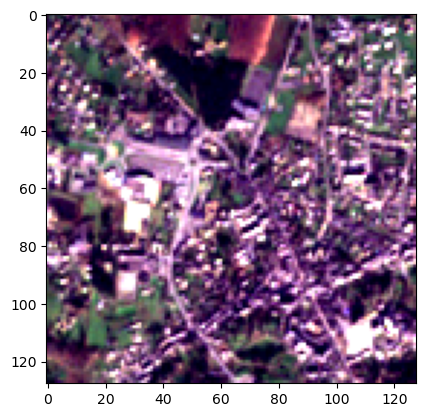

In [58]:
b, t = 1, 0
plt.imshow(utils_data.to_RGB(inputs[0][b,:,t,:,:]))

In [70]:
b, t , c = 0,25,0
print(inputs[0][b,c,t,:,:].mean())

tensor(1.3944)


In [73]:
s2_tensor[0,0].mean()

tensor(272.6547)

In [97]:
import yaml

with open("/home/hkerino/Documents/next_oso/configs/models/UTAE.yaml", "r") as f:
    config_utae = yaml.safe_load(f)

UTAE_encoder = UTAE.UTAE(**config_utae["encoder"])

# Decoder
MLP_Decoder = utils_model.MLPDecoder(**config_utae["decoder"])

criterion_ce = torch.nn.CrossEntropyLoss(ignore_index=0)

best_classifier_UTAE = lightning_module.classifier.load_from_checkpoint(
    "/home/hkerino/Documents/next_oso/logs/todel/epoch=116-step=31707.ckpt",
    weights_only=True,
    encoder=UTAE_encoder,
    decoder=MLP_Decoder,
    loss_fn=criterion_ce,
    batch_size=batch_size,
    mask_need=False,
)
trainer = L.Trainer(logger=False, callbacks=[])
predictions_UTAE = trainer.predict(best_classifier_UTAE, dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

In [105]:
y_true = []
x_img = []
for batch in dl_test:
    y_true.append(batch[1])

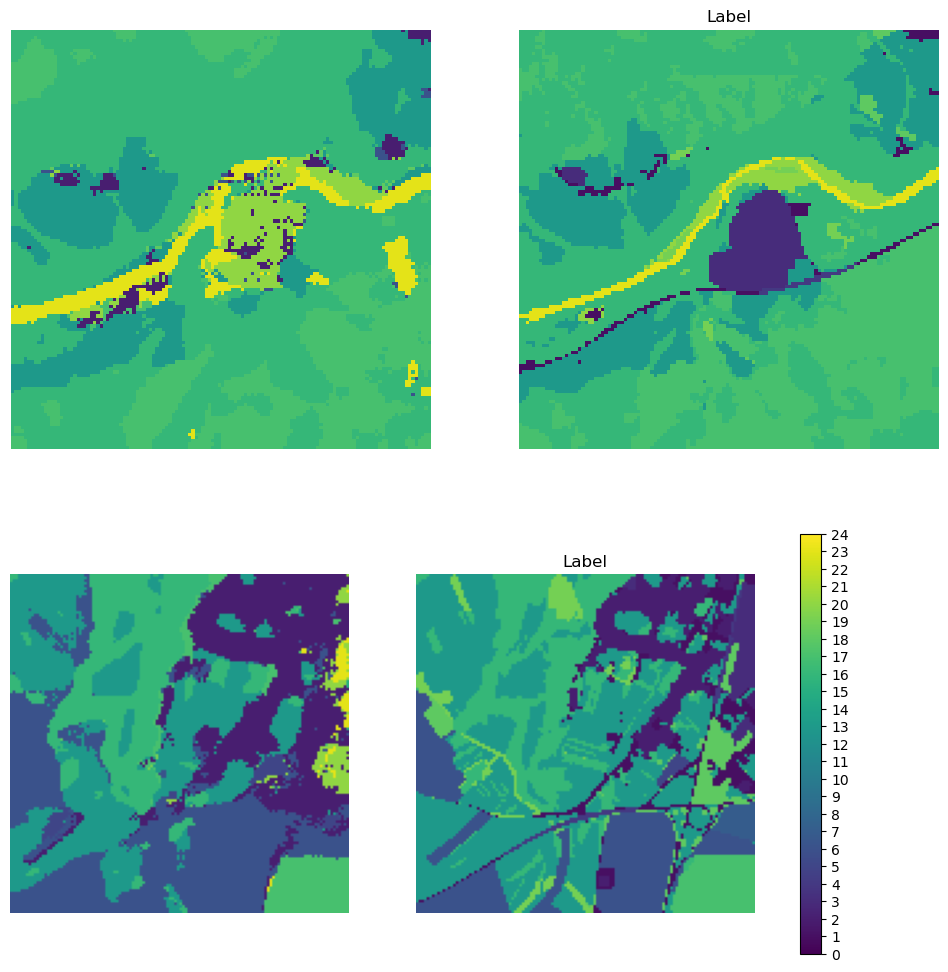

In [133]:
pred = torch.argmax(predictions_UTAE[0], dim=1)
label = y_true[0]
batch_size = predictions_UTAE[0].shape[0]
fig, axes = plt.subplots(batch_size, 2, figsize=(12, 6 * batch_size))

for b in range(batch_size):
    im = axes[b, 0].imshow(pred[b].cpu(), vmin=0, vmax=24)
    axes[b, 0].axis("off")
    im = axes[b, 1].imshow(label[b].cpu(), vmin=0, vmax=24)
    axes[b, 1].set_title("Label")
    axes[b, 1].axis("off")
cbar = fig.colorbar(im, ax=axes[1], ticks=np.arange(0, 25))

In [129]:
y_true[0].shape

torch.Size([2, 128, 128])

TypeError: Invalid shape (2, 25, 128, 128) for image data

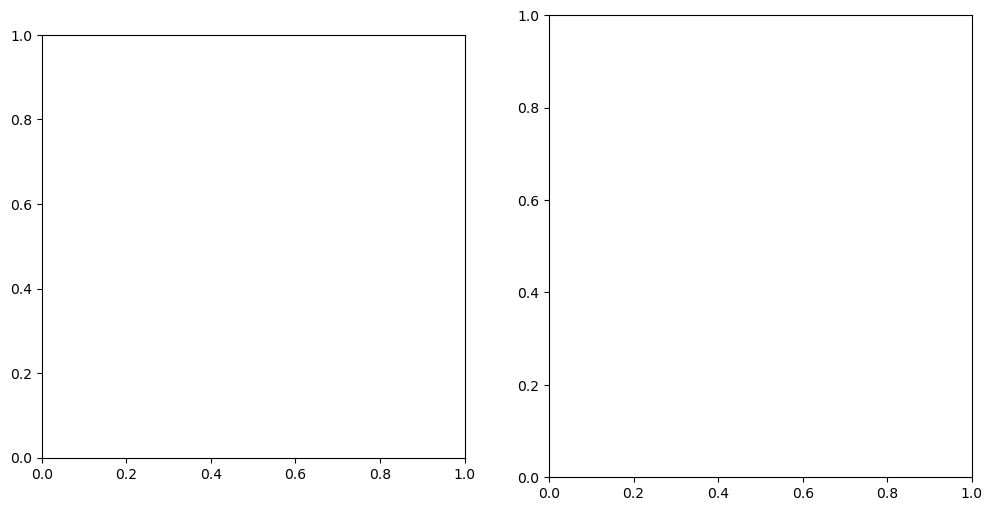

In [130]:
from analyse_results.utils_analyze import plot_predictions_single 

plot_predictions_single(pred=predictions_UTAE[0], label=y_true[0])

3

## Initial lr finding


In [4]:
batch_size = 2
dl_train, dl_val, dl_test = dataset.get_loaders(path_s2=PATH_TO_DATA_s2, path_mnt=PATH_MNT, path_label=PATH_TO_DATA_label, path_oso_class=PATH_TO_OSO_CLASSES, folds_train=[1], folds_val=[4], folds_test=[5], batch_size=2, num_worker=4, norm=True, norm_alise=False, shuffle=True, label_type='max_class', use_spatial_coords=False, mask_needed=False, sequence_packing=False, pass_id=False)

In [5]:
with open("/home/hkerino/Documents/next_oso/configs/models/UTAE.yaml", "r") as f:
    train_cfg = yaml.safe_load(f)

encoder = UTAE.UTAE(**train_cfg['encoder'])
decoder = utils_model.MLPDecoder(**train_cfg['decoder'])

classifier = lightning_module.classifier(
    encoder,
    decoder,
    batch_size=batch_size,
    loss_fn=torch.nn.CrossEntropyLoss(ignore_index=0),
    use_spatial_coords=False,
    lr=0.001
)

trainer = L.Trainer(profiler=False, logger=False, callbacks=[])

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`weights_only` was not set, defaulting to `False`.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Finding best initial lr:   0%|          | 0/100 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_steps=100` reached.
Restoring states from the checkpoint path at /home/hkerino/Documents/next_oso/.lr_find_6b72fe16-000a-4438-b16e-e3bc2ade4cd3.ckpt
Restored all states from the checkpoint at /home/hkerino/Documents/next_oso/.lr_find_6b72fe16-000a-4438-b16e-e3bc2ade4cd3.ckpt
Learning rate set to 1.5488166189124817e-05
/tmp/ipykernel_22750/1004624159.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


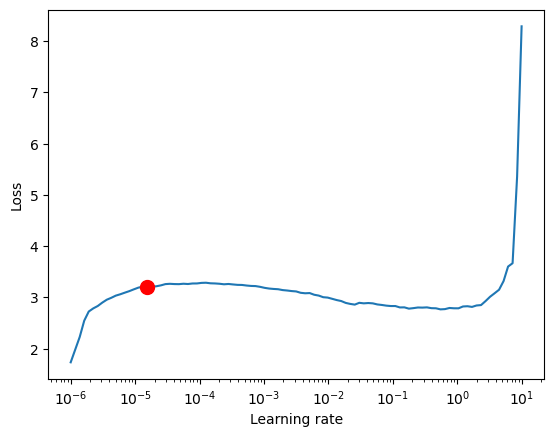

In [10]:
#LR finder
from lightning.pytorch.tuner import Tuner
tuner = Tuner(trainer)
lr_finder = tuner.lr_find(classifier, train_dataloaders=dl_train, val_dataloaders=dl_val, num_training=100, min_lr=1e-6, max_lr=10)

# Results can be found in
lr_finder.results

fig = lr_finder.plot(suggest=True)
fig.show()

In [9]:
lr_finder.results

{'lr': [1e-08,
  1.4454397707459274e-08,
  1.7378008287493753e-08,
  2.0892961308540398e-08,
  2.51188643150958e-08,
  3.019951720402016e-08,
  3.630780547701014e-08,
  4.36515832240166e-08,
  5.248074602497726e-08,
  6.309573444801934e-08,
  7.585775750291837e-08,
  9.120108393559096e-08,
  1.0964781961431852e-07,
  1.3182567385564074e-07,
  1.5848931924611133e-07,
  1.9054607179632475e-07,
  2.2908676527677735e-07,
  2.7542287033381663e-07,
  3.311311214825911e-07,
  3.9810717055349735e-07,
  4.786300923226383e-07,
  5.75439937337157e-07,
  6.918309709189366e-07,
  8.317637711026709e-07,
  1e-06,
  1.2022644346174132e-06,
  1.445439770745928e-06,
  1.7378008287493761e-06,
  2.089296130854039e-06,
  2.5118864315095797e-06,
  3.0199517204020163e-06,
  3.630780547701014e-06,
  4.365158322401661e-06,
  5.248074602497728e-06,
  6.3095734448019305e-06,
  7.585775750291836e-06,
  9.120108393559096e-06,
  1.0964781961431852e-05,
  1.3182567385564076e-05,
  1.584893192461114e-05,
  1.90546071

## Alise embedding

In [21]:
import json

m = json.load(
    open("/home/hkerino/Documents/nextoso-dataset/data/10m/s2/file_mapping.json", "r")
)
print(m)
emb_files = sorted(os.listdir("/home/hkerino/Documents/model_data/embeddings"))
emb_files
fold = [1, 5]
embedding_files_test = [
    f for f in emb_files if m[f"s2_{f.split('_')[1].split('.')[0]}.nc"]["fold"] in fold
]
print(embedding_files_test)
m[f"s2_{emb_files[0].split('_')[1].split('.')[0]}.nc"]["fold"]
torch.load(("/home/hkerino/Documents/model_data/embeddings/emb_3000.pt")).shape


{'s2_0871.nc': {'folder': 1, 'fold': 1}, 's2_1689.nc': {'folder': 1, 'fold': 1}, 's2_2884.nc': {'folder': 1, 'fold': 1}, 's2_3541.nc': {'folder': 1, 'fold': 1}, 's2_0795.nc': {'folder': 1, 'fold': 1}, 's2_1137.nc': {'folder': 1, 'fold': 1}, 's2_2059.nc': {'folder': 1, 'fold': 1}, 's2_1867.nc': {'folder': 1, 'fold': 1}, 's2_0044.nc': {'folder': 1, 'fold': 1}, 's2_2351.nc': {'folder': 1, 'fold': 1}, 's2_2177.nc': {'folder': 1, 'fold': 1}, 's2_0348.nc': {'folder': 1, 'fold': 1}, 's2_1555.nc': {'folder': 1, 'fold': 1}, 's2_2187.nc': {'folder': 1, 'fold': 1}, 's2_1437.nc': {'folder': 1, 'fold': 1}, 's2_2414.nc': {'folder': 1, 'fold': 1}, 's2_1496.nc': {'folder': 1, 'fold': 1}, 's2_0699.nc': {'folder': 1, 'fold': 1}, 's2_1337.nc': {'folder': 1, 'fold': 1}, 's2_1591.nc': {'folder': 1, 'fold': 1}, 's2_0245.nc': {'folder': 1, 'fold': 1}, 's2_0712.nc': {'folder': 1, 'fold': 1}, 's2_1514.nc': {'folder': 1, 'fold': 1}, 's2_0113.nc': {'folder': 1, 'fold': 1}, 's2_0907.nc': {'folder': 1, 'fold': 1},

torch.Size([10, 64, 128, 128])

In [30]:
from Alise.decode_embedding import alise_embedding_dataset, AliseEmbeddingDataModule

d = alise_embedding_dataset(
    path_embeddings="/home/hkerino/Documents/model_data/embeddings/",
    path_labels=PATH_TO_DATA_label,
    path_mapping_folder=PATH_TO_DATA_s2,
    fold=None
)

dm =AliseEmbeddingDataModule(
    path_embeddings="/home/hkerino/Documents/model_data/embeddings/",
    path_mapping_folder=PATH_TO_DATA_s2,
    path_labels=PATH_TO_DATA_label,
    fold_train=[1],
    fold_val=[2],
    fold_test=[3]
)

In [31]:
dm.data_train.__len__()

22

In [39]:
dt = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2,
    path_mnt=PATH_MNT,
    path_label=PATH_TO_DATA_label,
    path_oso_class=PATH_TO_OSO_CLASSES,
    norm=False,
    norm_pretrained_alise=True,
    remove_invalid_temp=True,
    folds=[1,2,3],
    label_type="probas",
    return_id=True,
)
dt.__len__()


2163

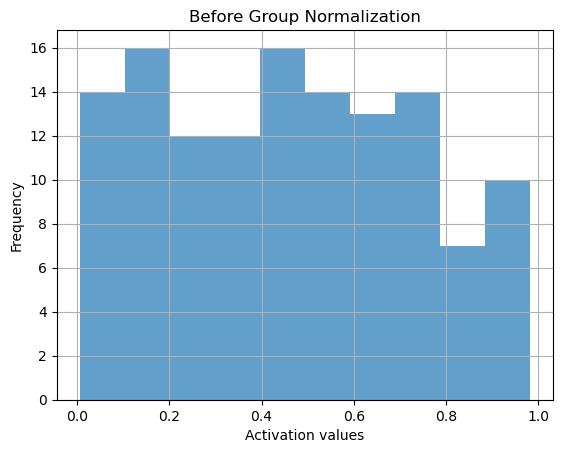

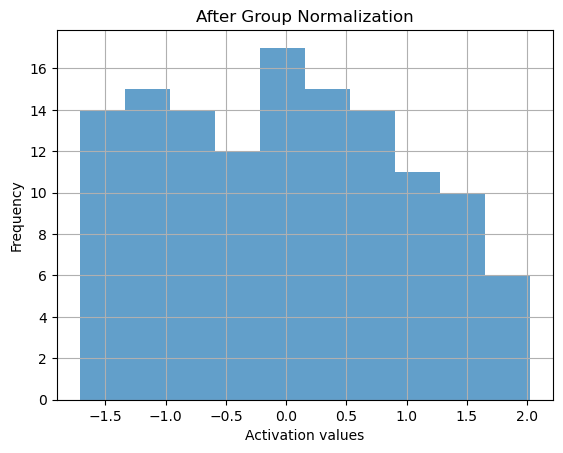

In [14]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


# Helper function to plot activation distributions
def plot_activation_distributions(tensor, title=""):
    flattened = tensor.flatten().cpu().numpy()
    plt.hist(flattened, bins=10, alpha=0.7)
    plt.title(title)
    plt.xlabel("Activation values")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.show()


# Group Normalization setup
group_norm = nn.GroupNorm(num_groups=2, num_channels=8)

# Create random tensor
x = torch.rand(1, 8, 4, 4)  # Shape: [1, 8, 4, 4]

# Apply Group Normalization
normalized = group_norm(x)

# Plot distributions before and after GN
plot_activation_distributions(x, "Before Group Normalization")
plot_activation_distributions(normalized.detach(), "After Group Normalization")

## Pastis

In [3]:
from pastis.pastis_dataset import PASTIS_Dataset, pad_pastis_collate, get_loaders_pastis
PATH_TO_PASTIS = "/home/hkerino/Documents/PASTIS"
dt = PASTIS_Dataset(PATH_TO_PASTIS, norm=True)

Reading patch metadata . . .
Done.
Dataset ready.


In [5]:
import json

json.load(open(os.path.join(PATH_TO_PASTIS, "label_names.json"))).values()


dict_values(['Background', 'Meadow', 'Soft winter wheat', 'Corn', 'Winter barley', 'Winter rapeseed', 'Spring barley', 'Sunflower', 'Grapevine', 'Beet', 'Winter triticale', 'Winter durum wheat', 'Fruits,  vegetables, flowers', 'Potatoes', 'Leguminous fodder', 'Soybeans', 'Orchard', 'Mixed cereal', 'Sorghum', 'Void label'])

In [4]:
dt.__getitem__(0)[0][1]

{'S2': tensor([ 23,  28,  33,  38,  48,  53,  58,  68,  73,  78,  83, 138, 143, 168,
         173, 178, 193, 208, 223, 233, 238, 253, 268, 273, 278, 293, 298, 303,
         308, 313, 318, 333, 343, 348, 353, 358, 363, 368, 378, 383, 388, 403,
         413])}

In [9]:
label.shape

torch.Size([4, 128, 128])

In [4]:
dl_train, dl_val, dl_test = get_loaders_pastis(PATH_TO_PASTIS, 4)

Reading patch metadata . . .
Done.
Dataset ready.
Reading patch metadata . . .
Done.
Dataset ready.
Reading patch metadata . . .
Done.
Dataset ready.


In [6]:
inputs, label = next(iter(dl_train))

In [9]:
inputs[0].shape

torch.Size([4, 10, 61, 128, 128])

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /home/hkerino/Documents/next_oso/checkpoints exists and is not empty.

  | Name           | Type                      | Params | Mode  | FLOPs
-----------------------------------------------------------------------------
0 | encoder        | UTAE                      | 854 K  | train | 0    
1 | decoder        | MLPDecoder           

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `val_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: 

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `test_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

[{}]

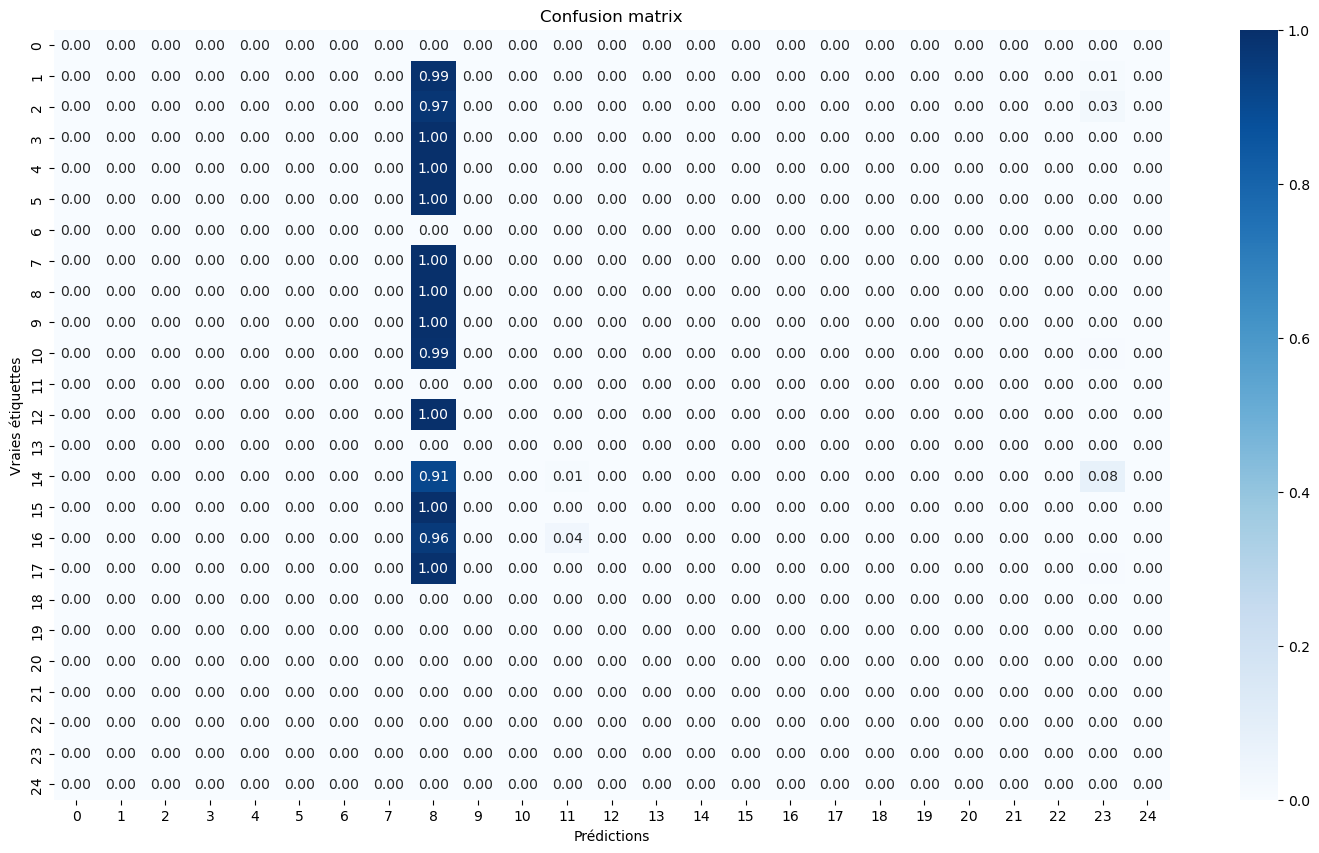

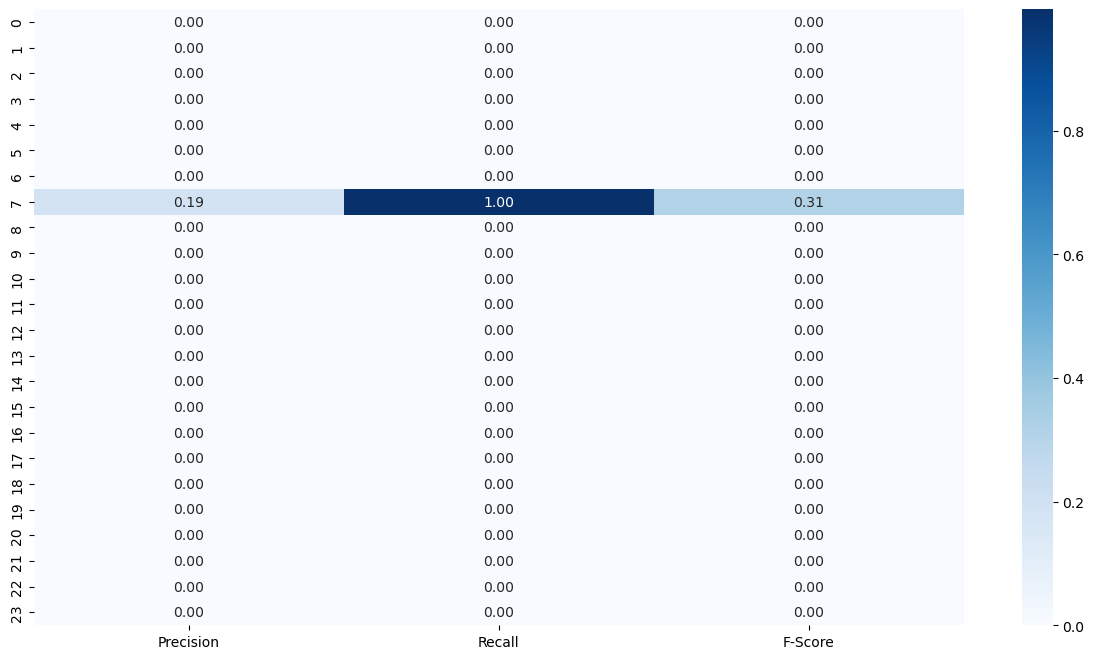

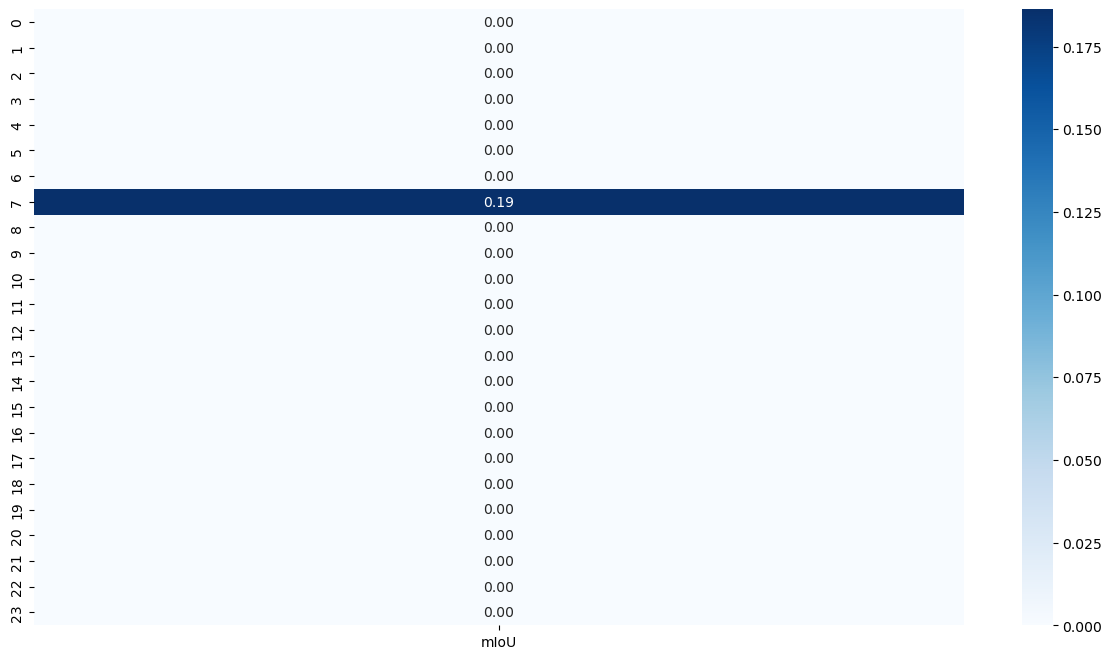

In [5]:
UTAE_encoder = UTAE.UTAE(
    input_dim=10,
    encoder_widths=[32, 64, 128],
    decoder_widths=[64, 64, 128],
    out_conv=[32, 25],
    str_conv_k=4,
    str_conv_s=2,
    str_conv_p=1,
    agg_mode="att_group",
    encoder_norm="group",
    n_head=16,
    d_model=128,
    d_k=8,
    encoder=True,
    return_maps=False,
    pad_value=0,
    padding_mode="reflect",
)

MLP_Decoder = utils_model.MLPDecoder(mlp=[64, 32, 25], dropout=0.2)

classifier = lightning_module.classifier(
    UTAE_encoder,
    MLP_Decoder,
    batch_size=2,
    loss_fn=torch.nn.CrossEntropyLoss(ignore_index=0)
)

trainer = L.Trainer(
    max_epochs=1,
    profiler=False,
    logger=False,
    callbacks=[],
    limit_train_batches=2,
    limit_val_batches=2,
    limit_test_batches=2,
)
trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.

  | Name           | Type                      | Params | Mode  | FLOPs
-----------------------------------------------------------------------------
0 | encoder        | ALISE                     | 1.0 M  | train | 0    
1 | decoder        | MLPDecoder                | 1.9 K  | train | 0    
2 | loss_fn        | CrossEntropyLoss          | 0      | train | 0    
3 | acc_metric     | MulticlassAccuracy        | 0      | train | 0    
4 | cm_metric      | MulticlassConfusionMatrix | 0 

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1` reached.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `test_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/home/hkerino/Documents/next_oso/.pixi/envs/default/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

[{}]

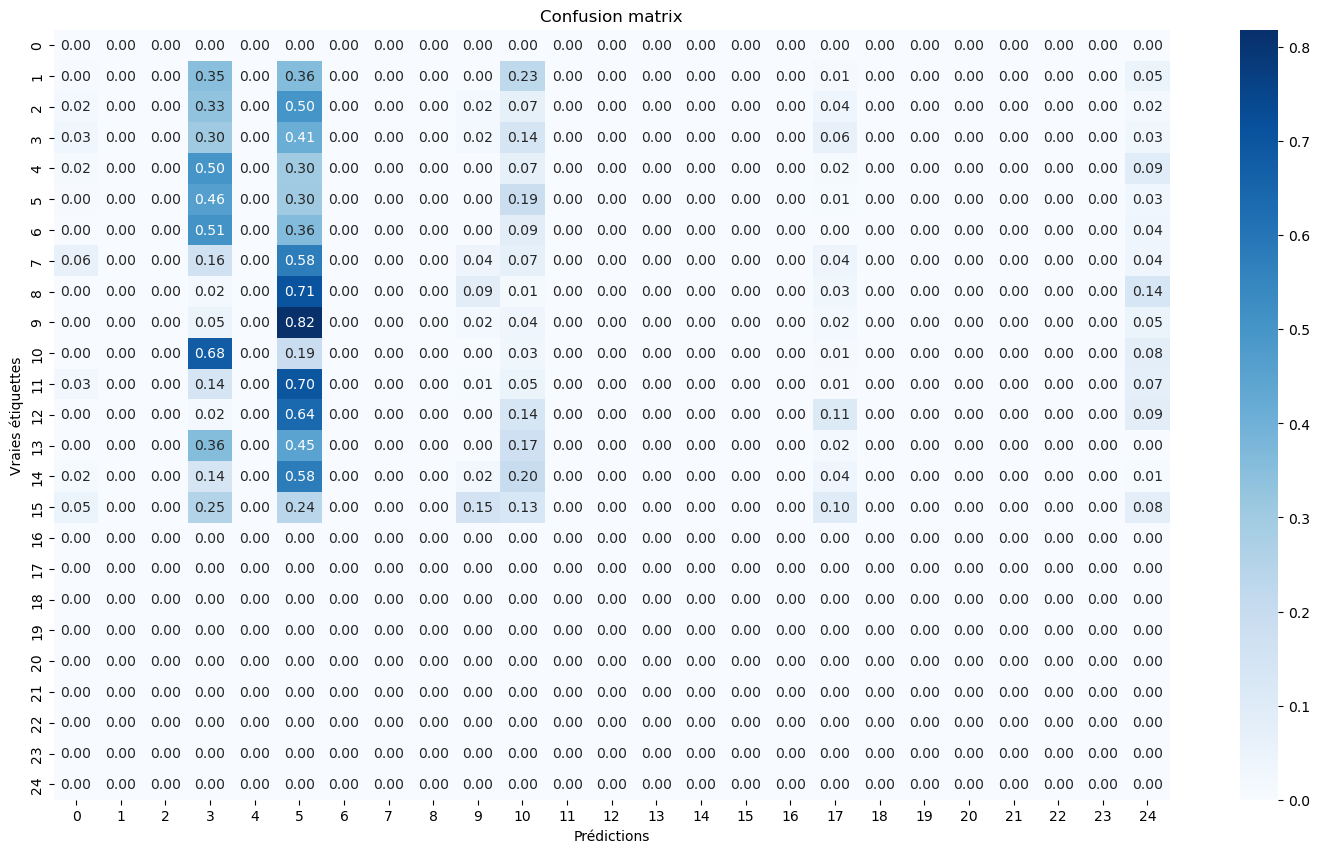

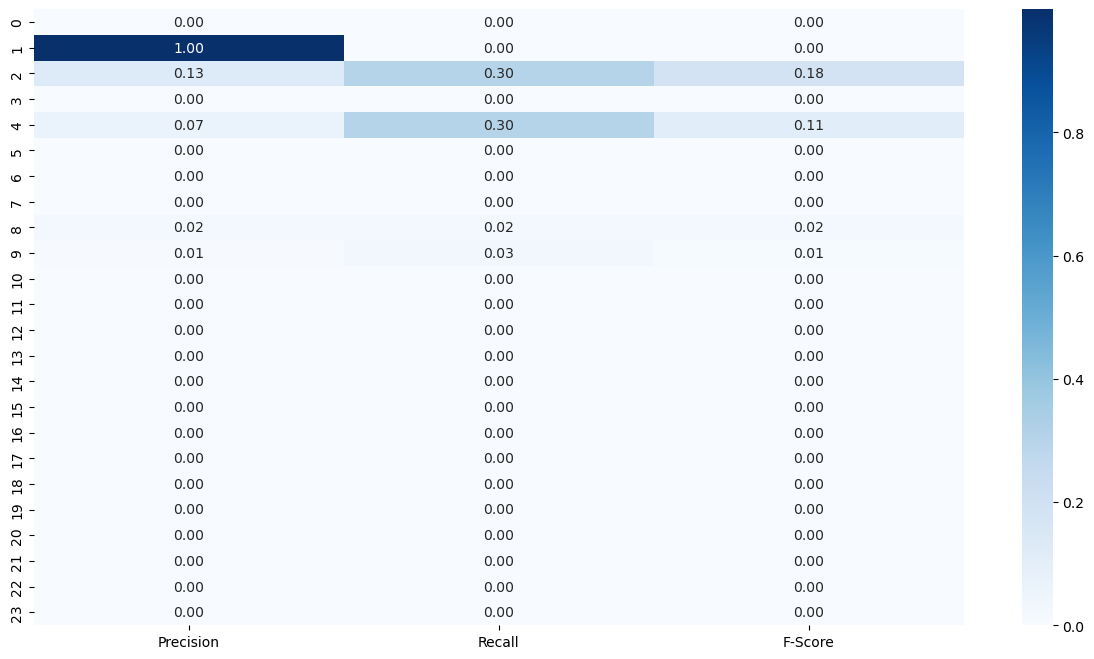

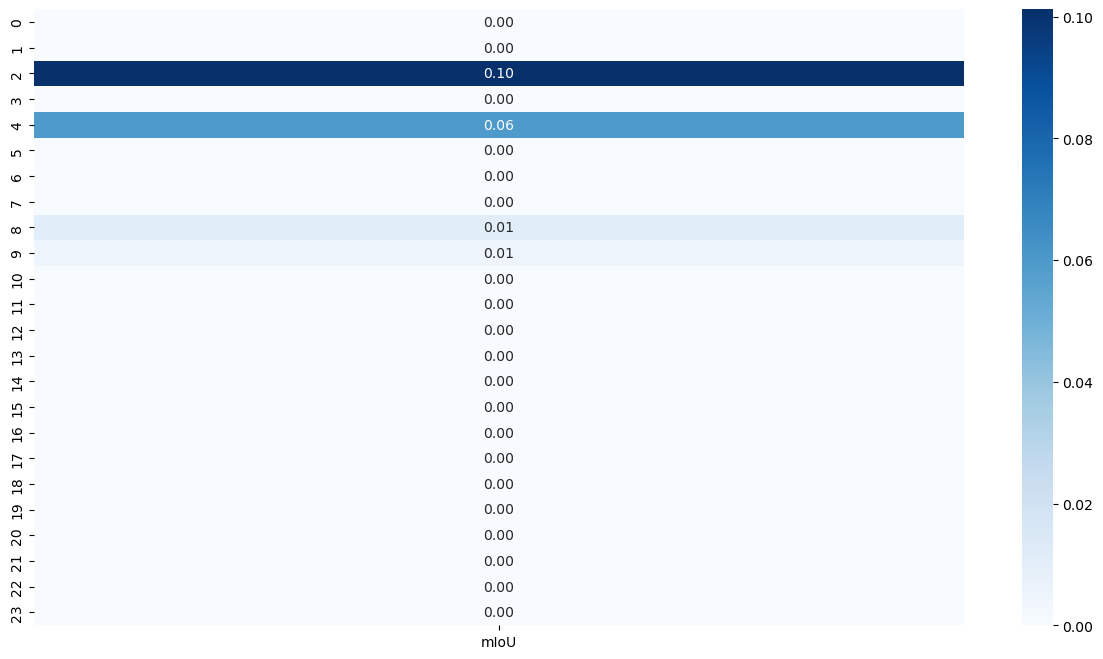

In [7]:
from Alise import ALISE, sse, transformer, temporal_proj
embedding_dim = 32
embbeding_model = sse.PatchEmbedding(
    sse=sse.Unet(
        inplanes=10,
        planes=embedding_dim,
        encoder_widths=[64, 64, 64, 128],
        decoder_widths=[32, 32, 64, 128],
        encoder_norm="group",
        padding_mode="reflect",
        decoding_norm="group",
        return_maps=False,
        str_conv_k=4,
        str_conv_s=2,
        str_conv_p=1,
        skip_conv_norm="group",
    ),
    tpe=sse.PositionalEncoder(d=embedding_dim),
)

transformer_model = transformer.Transformer(
    d_model=embedding_dim,
    nhead=4,
    dim_feedforward=embedding_dim * 2,
    dropout=0.2,
    batch_first=True,
    num_layers=1,
)

temp_proj_model = temporal_proj.LearnedQMultiHeadAttention(
    n_head=8, d_k=8, d_in=embedding_dim, n_q=1
)

ALISE_encoder = ALISE.ALISE(
    patch_embedding=embbeding_model,
    temporal_encoder=transformer_model,
    temporal_projector=temp_proj_model,
)

MLP_Decoder = utils_model.MLPDecoder(mlp=[embedding_dim, 32, 25], dropout=0.2)


classifier = lightning_module.classifier(
    ALISE_encoder,
    MLP_Decoder,
    batch_size=2,
    loss_fn=torch.nn.CrossEntropyLoss(ignore_index=0),
)

trainer = L.Trainer(
    max_epochs=1,
    profiler=False,
    logger=False,
    callbacks=[],
    limit_train_batches=2,
    limit_val_batches=2,
    limit_test_batches=2,
)
trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)

In [ ]:
import json

json.load(open())
